# Plasticity plotting

This notebook generates plots to visualize neural plasticity post-patching by comparing outputs of a model finetuned using baseline data for baseline and post-patching data. The inference data is expected to exist under settings.INFERENCE_DIR, organized by model name and fold. The notebook allows you to specify which subjects and conditions to visualize.

In [1]:
import os

import numpy as np
from core import plotting
from core import io
from core import settings
from core import utils
import matplotlib.pyplot as plt
from scipy.stats import sem, ttest_rel, wilcoxon
import mne
from core import plot_data_processing as data_processor

In [2]:
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

model_name = "masking_10_19"
subjects = None # set to None to load all subjects
conditions = ["right_3"]  # set to None to load all conditions
id_low, id_high = None, None
trial_ids = [i for i in range(id_low, id_high)] if id_low is not None and id_high is not None else None #[]  # set to None to load all trial ids
bands = None #[] # set to None to visualize all frequency bands
exclude_left_patched = True
exclude_right_patched_lefties = True # set to True to exclude subjects with left eye dominance and right patching
exclude_button_press = False # set to True to exclude button press trials (everything before STMD59)
time_window = "analysis" # set which time window to analyze, options are "analysis" and "full"
topomap_vlim = None # colour scale of the effect-size topomaps: None = one symmetric scale per figure from its largest |value|, a number (e.g. 0.5) = the same fixed scale in all topomap figures


In [3]:
# select appropriate frequency bands based on user input
if bands is None:
    bands = list(settings.FREQ_BANDS.keys())
else:
    loaded = []
    for band in bands:
        for key in settings.FREQ_BANDS.keys():
            if band in key:
                loaded.append(key)
    bands = loaded

# select subjects to exclude based on eye dominance, button press, and patching side
exclude_subjects = list(settings.EXCLUDED_SUBJECTS)
if exclude_left_patched:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT/"eye_dominance.csv"))
if exclude_right_patched_lefties:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT/"rightpatch_eye_dominance.csv")) # after STMD35, all patches were on the right eye, so exclude lefties
if exclude_button_press:
    press_subjects = [subj for subj in io.get_stored_subject_names(settings.DATA_ROOT) if utils.subject_paradigm(subj, settings.NO_PRESS_FROM_SUBJECT) == "press"]
    exclude_subjects.extend(press_subjects)
    print(exclude_subjects)

an_suffix = "window"
if time_window == "analysis":
    an_suffix+= "_analysis"
elif time_window == "full":
    an_suffix+= "_full"

excl_suffix = "excl"
if exclude_left_patched:
    excl_suffix+= "_left"
if exclude_right_patched_lefties:
    excl_suffix+= "_rightlefties"
if exclude_button_press:
    excl_suffix+= "_buttonpress"
if excl_suffix == "excl":
    excl_suffix = ""

# every plot of this notebook is saved under {model_name}/{conditions}/{plot type}/
plot_root = settings.PLOT_INFERENCE / model_name / ("_".join(conditions) if conditions else "all_conditions")

if trial_ids is not None:
    plot_root = plot_root / f"trial_{id_low}-{id_high}"


### Filter the inference data to only include the specified subjects, conditions, and trial ids

In [4]:
def load_filtered_merged(stim_patch: str):
    baseline_merged = []
    postpatch_merged = []

    for i in range(1, 7):
        b_file_path = settings.INFERENCE_DIR / model_name / str(i) / "baseline_reconstruction.h5"
        p_file_path = settings.INFERENCE_DIR / model_name / str(i) / "postpatch_reconstruction.h5"

        b_fold_trials = io.load_inference_trials(b_file_path, subjects=subjects, conditions=conditions, idxs=trial_ids, exclude_subjects=exclude_subjects, window=time_window, stim_patch=stim_patch)
        baseline_merged.extend(b_fold_trials)
        p_fold_trials = io.load_inference_trials(p_file_path, subjects=subjects, conditions=conditions, idxs=trial_ids, exclude_subjects=exclude_subjects, window=time_window, stim_patch=stim_patch)
        postpatch_merged.extend(p_fold_trials)
    return baseline_merged, postpatch_merged

baseline_merged, postpatch_merged = load_filtered_merged("post")
baseline_merged_pre, postpatch_merged_pre = load_filtered_merged("pre")


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: right_

### Power-corrected MAE
In dB, a channel's error shrinks when its power rises with a component the model predicts, and grows when its power falls (see the injection test), so a change in power shows up as a change in MAE. `fill_corrected_maes` removes that dependence:
power level (`signal_mean`, the mean dB of the target) and MAE are centered within each subject and session, one line per band is fitted on the centered trials of all subjects, and every trial's MAE is corrected to the mean baseline power:
`corrected MAE = MAE - slope * (power - mean baseline power)`.
It runs separately for the post- and the pre-stimulus patch, and the whole tensor and every channel are corrected separately (own slopes and reference power). The results are stored in `corrected_mae` / `corrected_mae_bandwise` of `trial.metrics` and `trial.channel_metrics`.

In [5]:
slopes, channel_slopes = data_processor.fill_corrected_maes(baseline_merged, postpatch_merged, bands)

slopes_pre, channel_slopes_pre = data_processor.fill_corrected_maes(baseline_merged_pre, postpatch_merged_pre, bands)

print("Global slopes (MAE per dB of power) and the range of the channel slopes:")
for patch, (patch_slopes, patch_channel_slopes) in {"post-stimulus": (slopes, channel_slopes), "pre-stimulus": (slopes_pre, channel_slopes_pre)}.items():
    print(patch)
    for band, slope in patch_slopes.items():
        ch_values = [patch_channel_slopes[ch][band] for ch in patch_channel_slopes]
        print(f"  {band:16s} {slope:.3f}   channel slopes: {np.nanmin(ch_values):.3f} - {np.nanmax(ch_values):.3f}")


Global slopes (MAE per dB of power) and the range of the channel slopes:
post-stimulus
  all bands        -0.013   channel slopes: -0.097 - -0.010
  theta (5-8Hz)    -0.096   channel slopes: -0.204 - -0.123
  alpha (8-12Hz)   -0.097   channel slopes: -0.202 - -0.123
  beta (12-30Hz)   -0.013   channel slopes: -0.105 - -0.034
  gamma (30-60Hz)  0.026   channel slopes: -0.052 - 0.038
pre-stimulus
  all bands        -0.011   channel slopes: -0.088 - -0.015
  theta (5-8Hz)    -0.093   channel slopes: -0.203 - -0.118
  alpha (8-12Hz)   -0.095   channel slopes: -0.189 - -0.125
  beta (12-30Hz)   -0.013   channel slopes: -0.102 - -0.029
  gamma (30-60Hz)  0.022   channel slopes: -0.053 - 0.026


# Plotting the difference between baseline and post-patching performance

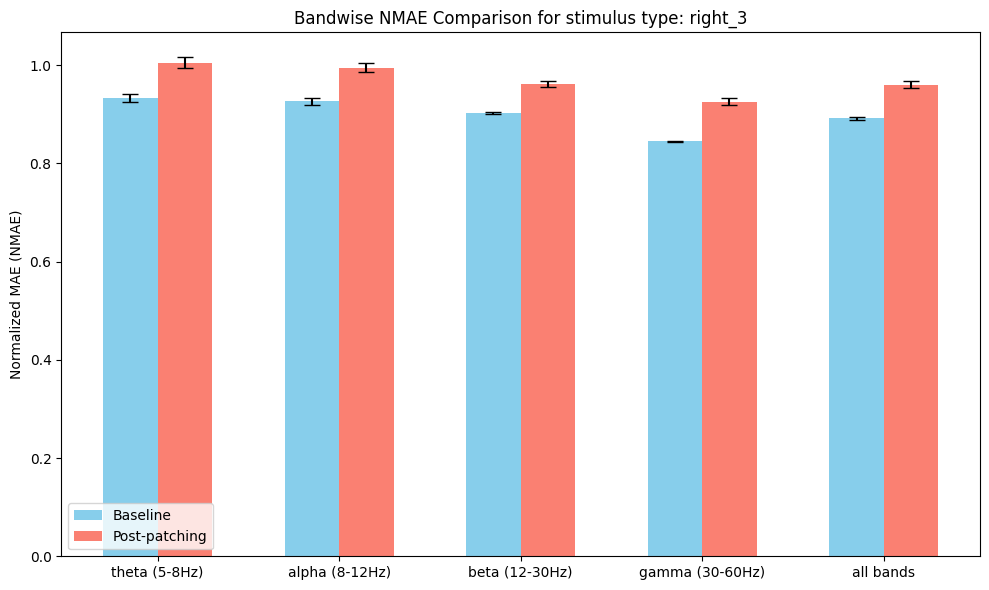

In [6]:



baseline_means, baseline_sems = data_processor.get_subjectwise_metric_mean(baseline_merged, metric_name="nmae", bands=settings.FREQ_BANDS)
postpatch_means, postpatch_sems = data_processor.get_subjectwise_metric_mean(postpatch_merged, metric_name="nmae", bands=settings.FREQ_BANDS)

title = f'Bandwise NMAE Comparison for stimulus type: {", ".join(conditions)}'
width = 0.3

means = [baseline_means.values(), postpatch_means.values()]
sems = [baseline_sems.values(), postpatch_sems.values()]
comparison_labels = ["Baseline", "Post-patching"]

fig, ax = plotting.plot_grouped_bar(x_text=baseline_means.keys(), width=width, means=means, sems=sems, labels=comparison_labels, title=title)
plotting.save_button(fig, save_dir=plot_root / "bandwise_e_comparison", default_name=f"error_{an_suffix}_{excl_suffix}")


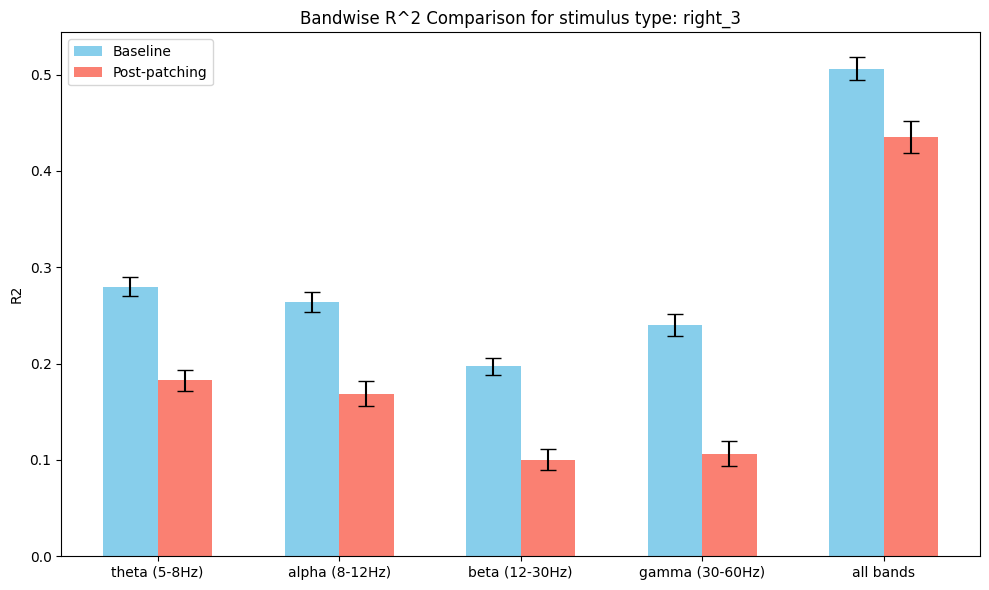

In [7]:


baseline_means, baseline_sems = data_processor.get_subjectwise_metric_mean(baseline_merged, metric_name="r2_bandwise", bands=settings.FREQ_BANDS)
postpatch_means, postpatch_sems = data_processor.get_subjectwise_metric_mean(postpatch_merged, metric_name="r2_bandwise", bands=settings.FREQ_BANDS)

title = f'Bandwise R^2 Comparison for stimulus type: {", ".join(conditions)}'
width = 0.3
y_label = "R2"

means = [baseline_means.values(), postpatch_means.values()]
sems = [baseline_sems.values(), postpatch_sems.values()]
comparison_labels = ["Baseline", "Post-patching"]

fig, ax = plotting.plot_grouped_bar(x_text=baseline_means.keys(), width=width, means=means, sems=sems, labels=comparison_labels, title=title, y_label=y_label)
plotting.save_button(fig, save_dir=plot_root / "bandwise_e_comparison", default_name=f"r2_error_{an_suffix}_{excl_suffix}")


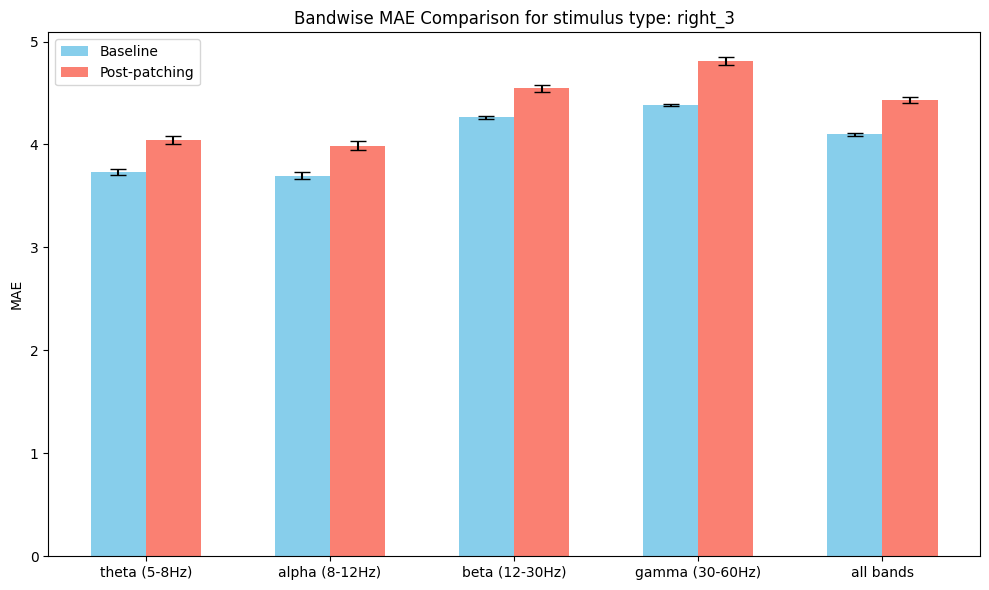

In [8]:
# Plotting the difference between baseline and post-patching performance


baseline_means, baseline_sems = data_processor.get_subjectwise_metric_mean(baseline_merged,
                                                                           metric_name="mae_bandwise",
                                                                           bands=settings.FREQ_BANDS)
postpatch_means, postpatch_sems = data_processor.get_subjectwise_metric_mean(postpatch_merged,
                                                                              metric_name="mae_bandwise",
                                                                              bands=settings.FREQ_BANDS)

title = f'Bandwise MAE Comparison for stimulus type: {", ".join(conditions)}'
width = 0.3
ylabel = "MAE"
ylim = None

means = [baseline_means.values(), postpatch_means.values()]
sems = [baseline_sems.values(), postpatch_sems.values()]
comparison_labels = ["Baseline", "Post-patching"]

fig, ax = plotting.plot_grouped_bar(x_text=baseline_means.keys(), width=width, means=means, sems=sems, labels=comparison_labels,
                                    title=title, y_label=ylabel, ylim=ylim)

plotting.save_button(fig, save_dir=plot_root / "bandwise_e_mae_comparison",
                     default_name=f"error_{an_suffix}_{excl_suffix}")

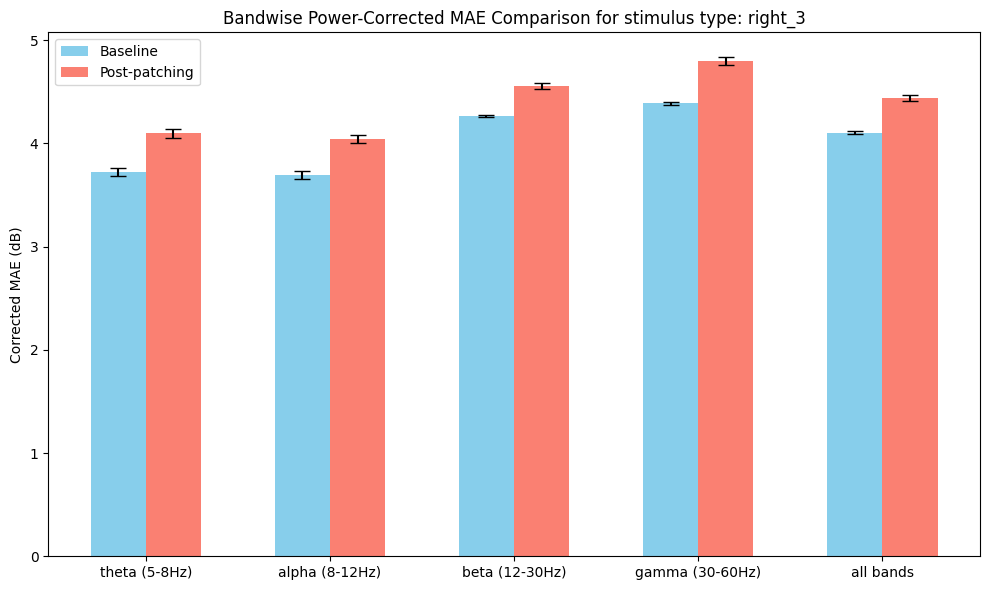

In [9]:
# power-corrected MAE of the post-stimulus patch (trial level, see fill_corrected_maes above)
baseline_means, baseline_sems = data_processor.get_subjectwise_metric_mean(baseline_merged, metric_name="corrected_mae_bandwise", bands=bands)
postpatch_means, postpatch_sems = data_processor.get_subjectwise_metric_mean(postpatch_merged, metric_name="corrected_mae_bandwise", bands=bands)

title = f'Bandwise Power-Corrected MAE Comparison for stimulus type: {", ".join(conditions)}'
width = 0.3
ylabel = "Corrected MAE (dB)"

means = [baseline_means.values(), postpatch_means.values()]
sems = [baseline_sems.values(), postpatch_sems.values()]
comparison_labels = ["Baseline", "Post-patching"]

fig, ax = plotting.plot_grouped_bar(x_text=baseline_means.keys(), width=width, means=means, sems=sems, labels=comparison_labels,
                                    title=title, y_label=ylabel)

plotting.save_button(fig, save_dir=plot_root / "bandwise_e_mae_comparison",
                     default_name=f"corrected_error_{an_suffix}_{excl_suffix}")


## Single channel comparison viewer

In [10]:
input_metrics = []

input_metrics.append(data_processor.get_channel_viewer_metrics(baseline_merged, []))  # metadata only, the viewer computes the errors of the shown window
input_metrics.append(data_processor.get_channel_viewer_metrics(postpatch_merged, []))

In [11]:

input_data = [baseline_merged, postpatch_merged]
styling_params = {
        "param_text": "",
        #"suptitle": f"Single channel reconstruction comparison for stimulus type: {', '.join(conditions)}",
        "suptitle": f"Single channel reconstruction comparison for stimulus type: ",
        "apply_log": False,
        "target_mode": "wavelet",
        "time_window": settings.PATCH_WINDOWS["post"],  # the viewed trials are post-stimulus patches, time axis relative to onset
        "analysis_window": settings.POST_TARGET_WINDOW,  # only the scored part is shown and the errors are computed from it
}
save_dir = plot_root / "single_channel_comparison"
plotting.single_channel_viewer(input_data, input_metrics, n_chans=settings.N_CHANNELS, styling_params=styling_params, save_dir=save_dir, bands=settings.FREQ_BAND_INDICES, freqs=settings.FREQS, an_suffix=an_suffix, excl_suffix=excl_suffix)

## Topomaps of the change after patching
Per channel and band, from the subjects' changes (post-patching - baseline) of their mean error over trials:
- **d_z** = mean / SD of the changes: how consistent the change is across subjects (d_z = t / sqrt(N) of a paired t-test).
- **mean change** in dB: how large the change is.

Positive = larger error after patching. Three maps per metric and effect size:
- **Session drift**: error of the pre-stimulus patch (-1.0 … -0.7 s). Nothing stimulus-related happens here, so it shows tonic changes between the sessions (cap refit, arousal).
- **Plasticity effect**: post-stimulus minus pre-stimulus error, i.e. the stimulus-locked change. The drift cancels in this difference.
- **Combined**: error of the post-stimulus patch (0 … 0.4 s), drift and plasticity together. For the mean change, combined = drift + plasticity effect.

A subject is left out of a channel only if that channel has no value in one of its sessions (interpolated in every trial of the session); it still counts for the other channels.
The power-corrected MAE is shown first, the uncorrected MAE second for comparison. `topomap_vlim` sets the colour scale of the d_z maps only; the mean-change maps always scale to their largest |value|.

In [12]:
# subject means {channel: {subject: {band: value}}} of every metric, per session and stimulus patch
subject_means = {}
for metric in ("corrected_mae", "mae", "signal_mean"):
    subject_means[metric] = {
        "baseline": {"post": data_processor.calc_subjectwise_channel_metric_stats(baseline_merged, bands, metric, group_by='channel')[0],
                     "pre": data_processor.calc_subjectwise_channel_metric_stats(baseline_merged_pre, bands, metric, group_by='channel')[0]},
        "postpatch": {"post": data_processor.calc_subjectwise_channel_metric_stats(postpatch_merged, bands, metric, group_by='channel')[0],
                      "pre": data_processor.calc_subjectwise_channel_metric_stats(postpatch_merged_pre, bands, metric, group_by='channel')[0]},
    }

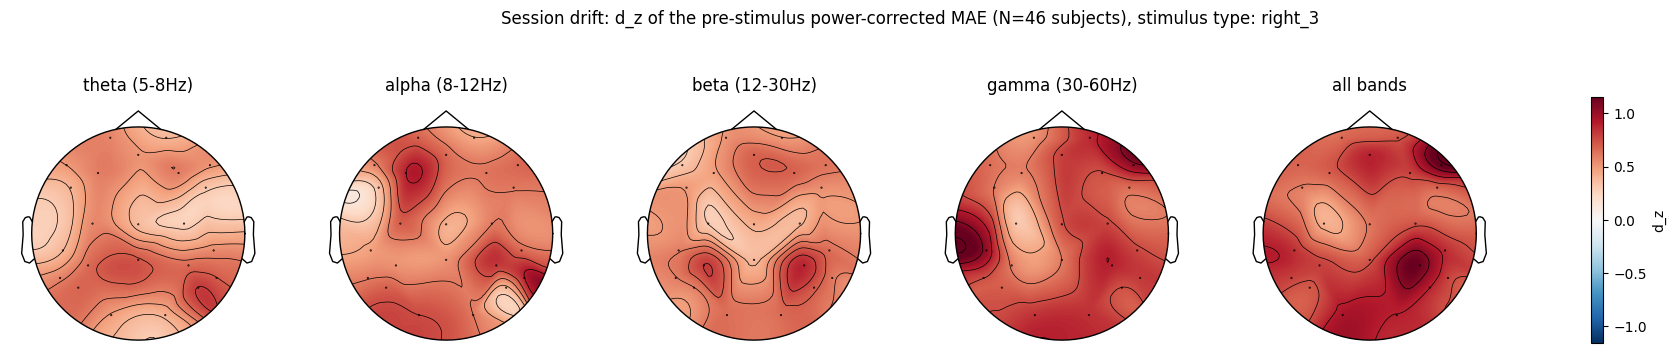

Session drift: d_z of the pre-stimulus power-corrected MAE, d_z:
  theta (5-8Hz)    max: T6 +0.80, PZ +0.71, A2 +0.70   min: C4 +0.27, F8 +0.33, CZ +0.37
  alpha (8-12Hz)   max: F3 +0.90, A2 +0.90, P4 +0.83   min: F7 +0.37, T6 +0.41, CZ +0.42
  beta (12-30Hz)   max: P4 +0.88, P3 +0.80, T6 +0.73   min: C3 +0.30, T1 +0.32, PZ +0.37
  gamma (30-60Hz)  max: T2 +1.02, T3 +1.00, P4 +0.89   min: C3 +0.32, FP1 +0.53, F3 +0.58
  all bands        max: T2 +1.16, P4 +1.13, O1 +0.94   min: C3 +0.41, F7 +0.59, CZ +0.62


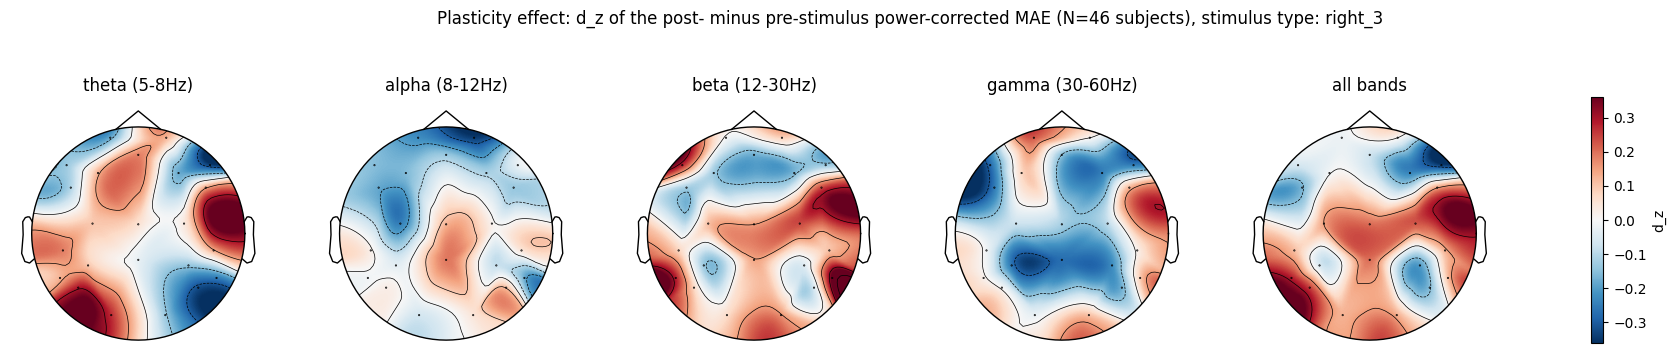

Plasticity effect: d_z of the post- minus pre-stimulus power-corrected MAE, d_z:
  theta (5-8Hz)    max: T5 +0.29, O1 +0.26, FZ +0.18   min: T2 -0.33, T6 -0.32, A2 -0.24
  alpha (8-12Hz)   max: PZ +0.19, CZ +0.13, T6 +0.10   min: FP2 -0.34, C3 -0.24, FP1 -0.22
  beta (12-30Hz)   max: A2 +0.36, A1 +0.27, T1 +0.26   min: FZ -0.18, F4 -0.16, P3 -0.14
  gamma (30-60Hz)  max: FP1 +0.22, F8 +0.12, O2 +0.09  min: PZ -0.27, T1 -0.27, P3 -0.27
  all bands        max: A1 +0.28, T5 +0.24, C4 +0.23   min: T2 -0.33, F4 -0.23, P4 -0.20


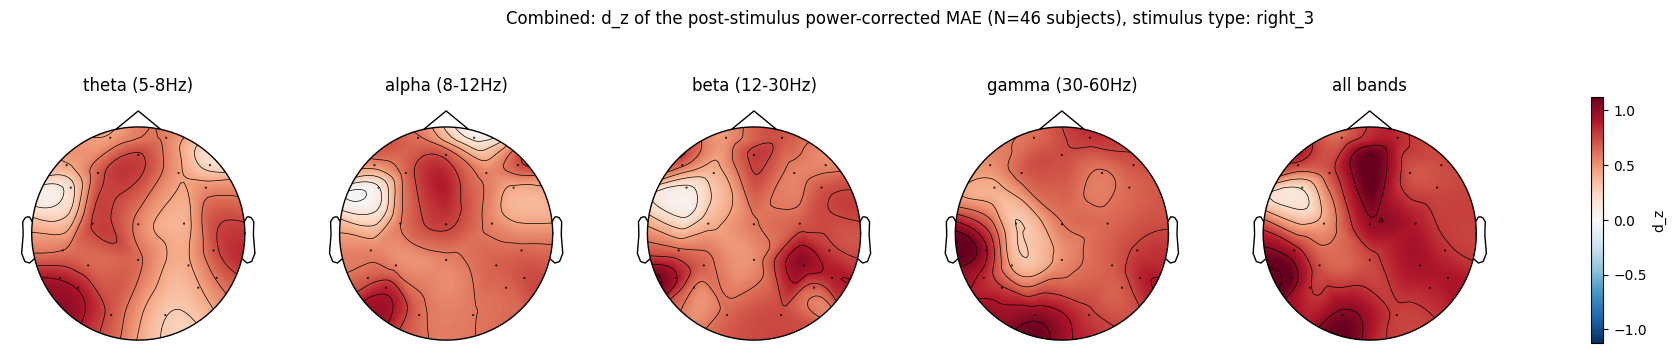

Combined: d_z of the post-stimulus power-corrected MAE, d_z:
  theta (5-8Hz)    max: T5 +0.89, A1 +0.88, FZ +0.76   min: T2 +0.23, F7 +0.24, O2 +0.31
  alpha (8-12Hz)   max: T5 +0.84, CZ +0.78, A2 +0.73   min: FP2 +0.10, F7 +0.14, F8 +0.43
  beta (12-30Hz)   max: P4 +1.00, A1 +0.92, A2 +0.88   min: F7 +0.11, F3 +0.38, C3 +0.39
  gamma (30-60Hz)  max: O1 +1.00, T3 +0.91, A1 +0.85   min: C3 +0.30, F7 +0.41, P3 +0.42
  all bands        max: FZ +1.13, A1 +1.10, O1 +1.05   min: F7 +0.22, C3 +0.47, FP1 +0.67


In [13]:
info = data_processor.create_topomap_info()  # 10-20 labels at the positions of the recording HydroCel electrodes
EFFECT_LABELS = {"d_z": "d_z", "mean": "mean change (dB)"}
CH_NAMES = [name.replace("EEG ", "").replace("-REF", "") for name in settings.CHORDER_STANDARD]


def plot_effect_topomaps(b_means, p_means, title, file_name, effect_size):
    """
    One topomap per band (+ all bands) of the change post-patching - baseline ("d_z" or "mean"), channels without a value are left out.
    Prints the 3 channels with the largest and the 3 with the smallest value of every band.
    """
    effect_by_band = data_processor.calc_subjectwise_channel_d(b_means, p_means, group_by_bands=True, effect_size=effect_size)
    # dict {"ch_0": value, ...} -> array in channel order, matching info
    vals_by_band = {band: np.array([effect[f"ch_{ch}"] for ch in range(settings.N_CHANNELS)]) for band, effect in effect_by_band.items()}
    # one symmetric colour scale shared by all bands, so the colours are comparable between the panels
    if effect_size == "d_z" and topomap_vlim is not None:
        max_val = topomap_vlim
    else:
        max_val = max(np.nanmax(np.abs(vals)) for vals in vals_by_band.values())

    n_subjects = len([s for s in b_means["ch_0"] if s in p_means["ch_0"]])
    draw_topomaps(vals_by_band, title, file_name, EFFECT_LABELS[effect_size], max_val, n_subjects)


def draw_topomaps(vals_by_band, title, file_name, label, max_val, n_subjects):
    """
    One topomap per band of {band: (n_chans,) values} on the colour scale -max_val to max_val, channels without a value are left out.
    Prints the 3 channels with the largest and the 3 with the smallest value of every band.
    """
    fig, axes = plt.subplots(1, len(vals_by_band), figsize=(max(6, 4.8 * len(vals_by_band)), 4))
    axes = np.atleast_1d(axes)
    for ax, (band, vals) in zip(axes, vals_by_band.items()):
        keep = np.flatnonzero(np.isfinite(vals))
        im, _ = mne.viz.plot_topomap(vals[keep], mne.pick_info(info, keep), axes=ax, show=False, vlim=(-max_val, max_val), cmap="RdBu_r")
        ax.set_title(band)
    fig.colorbar(im, ax=axes, shrink=0.8, label=label)
    plt.suptitle(f"{title} (N={n_subjects} subjects), stimulus type: {', '.join(conditions)}", y=1.02)
    plotting.save_button(fig, save_dir=plot_root / "bandwise_topomaps", default_name=f"{file_name}_{an_suffix}_{excl_suffix}")
    plt.show()

    # the 3 largest and 3 smallest channels of every band, channels without a value left out
    print(f"{title}, {label}:")
    for band, vals in vals_by_band.items():
        order = [ch for ch in np.argsort(vals) if np.isfinite(vals[ch])]
        largest = ", ".join(f"{CH_NAMES[ch]} {vals[ch]:+.2f}" for ch in order[::-1][:3])
        smallest = ", ".join(f"{CH_NAMES[ch]} {vals[ch]:+.2f}" for ch in order[:3])
        print(f"  {band:16s} max: {largest:30s} min: {smallest}")


def plot_session_contrasts(metric, label, effect_size):
    """The three topomaps of one metric and effect size: session drift, plasticity effect and combined."""
    b, p = subject_means[metric]["baseline"], subject_means[metric]["postpatch"]
    what = EFFECT_LABELS[effect_size]
    plot_effect_topomaps(b["pre"], p["pre"],
                         f"Session drift: {what} of the pre-stimulus {label}", f"{metric}_{effect_size}_drift", effect_size)
    plot_effect_topomaps(data_processor.subtract_channel_dicts(b["post"], b["pre"]), data_processor.subtract_channel_dicts(p["post"], p["pre"]),
                         f"Plasticity effect: {what} of the post- minus pre-stimulus {label}", f"{metric}_{effect_size}_plasticity", effect_size)
    plot_effect_topomaps(b["post"], p["post"],
                         f"Combined: {what} of the post-stimulus {label}", f"{metric}_{effect_size}_combined", effect_size)


plot_session_contrasts("corrected_mae", "power-corrected MAE", "d_z")

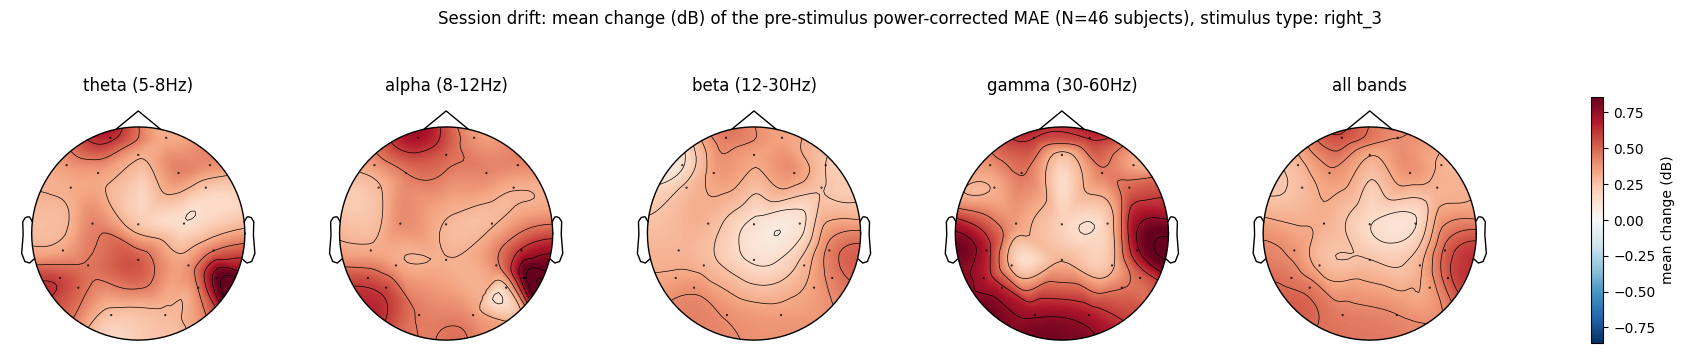

Session drift: mean change (dB) of the pre-stimulus power-corrected MAE, mean change (dB):
  theta (5-8Hz)    max: A2 +0.83, FP1 +0.63, A1 +0.56  min: C4 +0.16, CZ +0.23, F8 +0.24
  alpha (8-12Hz)   max: A2 +0.86, FP1 +0.71, T4 +0.62  min: T6 +0.26, C4 +0.29, F7 +0.29
  beta (12-30Hz)   max: FP1 +0.44, A2 +0.43, T4 +0.43  min: C4 +0.12, CZ +0.13, PZ +0.15
  gamma (30-60Hz)  max: O1 +0.73, T4 +0.72, A1 +0.68   min: CZ +0.20, C4 +0.22, P3 +0.26
  all bands        max: FP1 +0.54, A2 +0.53, T4 +0.50  min: C4 +0.15, CZ +0.16, PZ +0.24


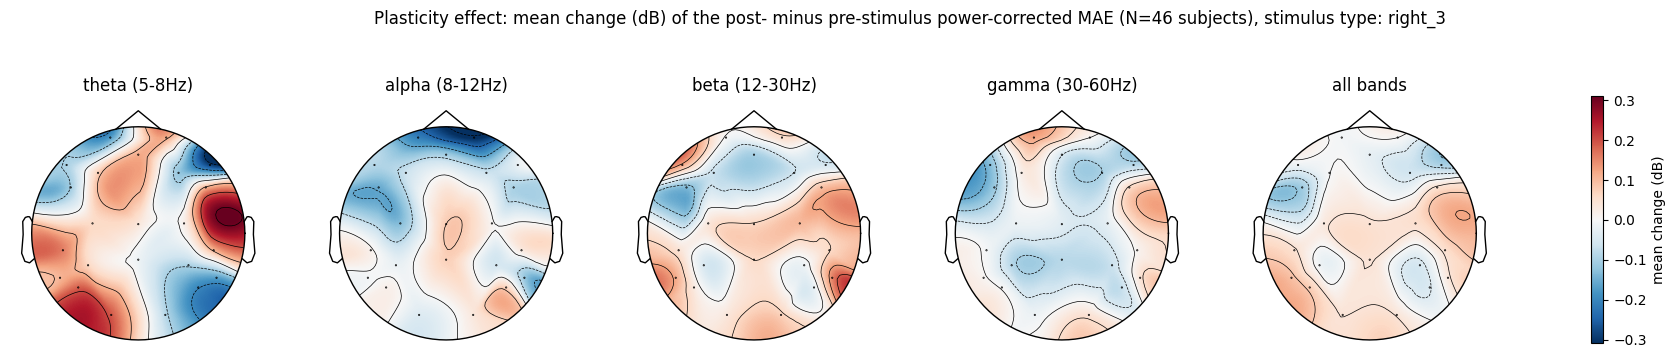

Plasticity effect: mean change (dB) of the post- minus pre-stimulus power-corrected MAE, mean change (dB):
  theta (5-8Hz)    max: O1 +0.18, T5 +0.18, T3 +0.15   min: T2 -0.28, T6 -0.20, A2 -0.16
  alpha (8-12Hz)   max: CZ +0.08, PZ +0.07, T6 +0.06   min: FP2 -0.31, FP1 -0.21, F7 -0.15
  beta (12-30Hz)   max: A2 +0.15, T1 +0.11, A1 +0.11   min: F7 -0.14, FZ -0.10, F3 -0.07
  gamma (30-60Hz)  max: FP1 +0.12, F8 +0.06, O2 +0.04  min: T1 -0.13, F7 -0.11, F4 -0.10
  all bands        max: A1 +0.09, T5 +0.07, C4 +0.05   min: F7 -0.10, T2 -0.10, F4 -0.06


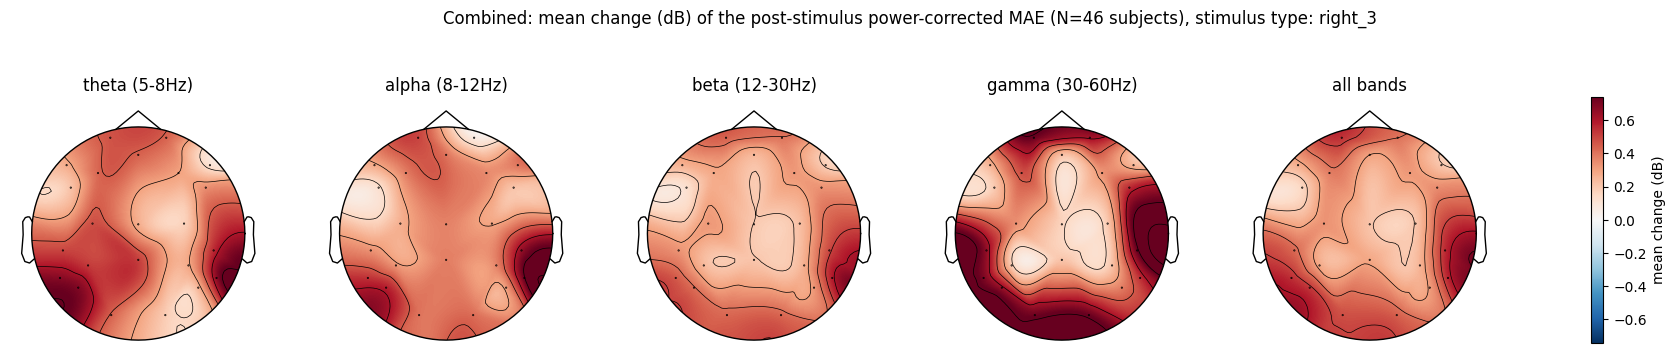

Combined: mean change (dB) of the post-stimulus power-corrected MAE, mean change (dB):
  theta (5-8Hz)    max: T5 +0.68, A1 +0.67, A2 +0.67   min: T2 +0.12, C4 +0.17, O2 +0.19
  alpha (8-12Hz)   max: A2 +0.74, T4 +0.65, T5 +0.57   min: FP2 +0.07, F7 +0.13, F8 +0.21
  beta (12-30Hz)   max: A2 +0.58, T4 +0.49, A1 +0.45   min: F7 +0.13, T2 +0.19, CZ +0.20
  gamma (30-60Hz)  max: T4 +0.73, FP1 +0.72, O2 +0.72  min: CZ +0.16, P3 +0.17, C4 +0.19
  all bands        max: A2 +0.56, T4 +0.55, A1 +0.54   min: F7 +0.17, C4 +0.21, T2 +0.21


In [14]:
plot_session_contrasts("corrected_mae", "power-corrected MAE", "mean")

### The same maps for the uncorrected MAE
For comparison: differences from the corrected maps above come from changes in power (the error shrinks where power rises and grows where it falls).

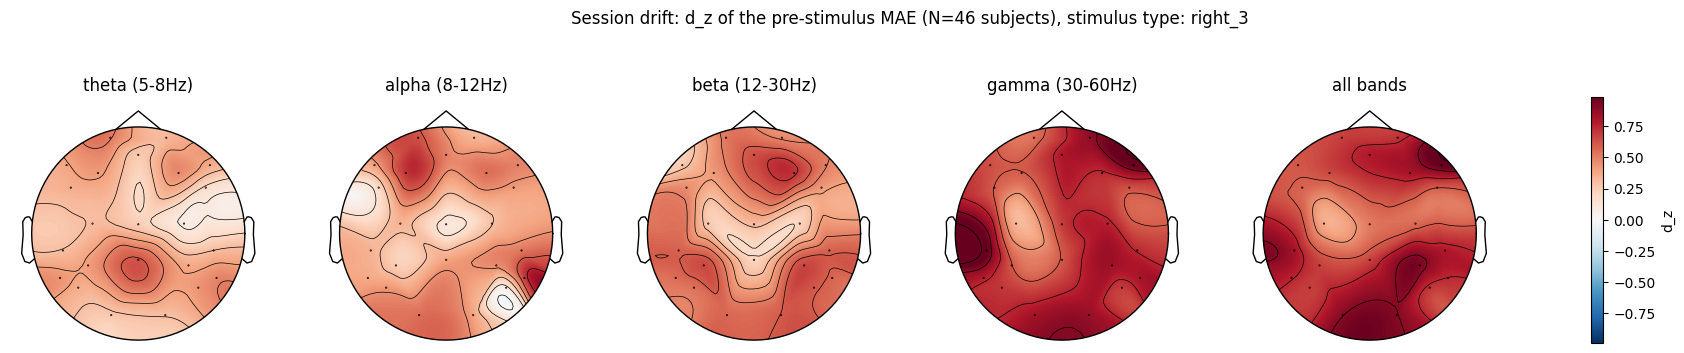

Session drift: d_z of the pre-stimulus MAE, d_z:
  theta (5-8Hz)    max: PZ +0.61, FP1 +0.51, A2 +0.48  min: C4 +0.08, F8 +0.18, CZ +0.24
  alpha (8-12Hz)   max: F3 +0.72, A2 +0.69, FP1 +0.63  min: T6 +0.11, CZ +0.11, F7 +0.22
  beta (12-30Hz)   max: F4 +0.72, P4 +0.66, P3 +0.65   min: PZ +0.21, C4 +0.21, C3 +0.26
  gamma (30-60Hz)  max: T3 +0.99, T2 +0.98, FP2 +0.87  min: C3 +0.33, FP1 +0.55, F3 +0.59
  all bands        max: T2 +0.99, P4 +0.94, O2 +0.91   min: C3 +0.37, CZ +0.52, C4 +0.56


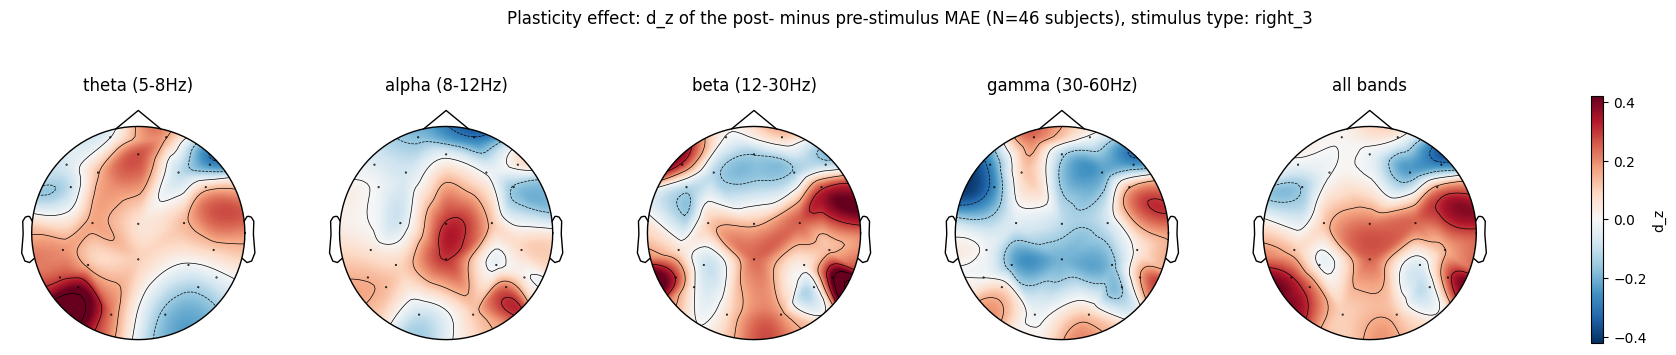

Plasticity effect: d_z of the post- minus pre-stimulus MAE, d_z:
  theta (5-8Hz)    max: T5 +0.40, A1 +0.28, FZ +0.27   min: T2 -0.25, O2 -0.17, T6 -0.12
  alpha (8-12Hz)   max: CZ +0.31, PZ +0.30, T6 +0.22   min: FP2 -0.30, FP1 -0.18, F8 -0.16
  beta (12-30Hz)   max: A2 +0.42, A1 +0.29, T1 +0.28   min: FZ -0.15, F4 -0.14, F3 -0.12
  gamma (30-60Hz)  max: FP1 +0.22, A2 +0.15, F8 +0.14  min: T1 -0.27, F7 -0.25, T2 -0.23
  all bands        max: A1 +0.31, A2 +0.26, PZ +0.24   min: T2 -0.27, F4 -0.22, F7 -0.14


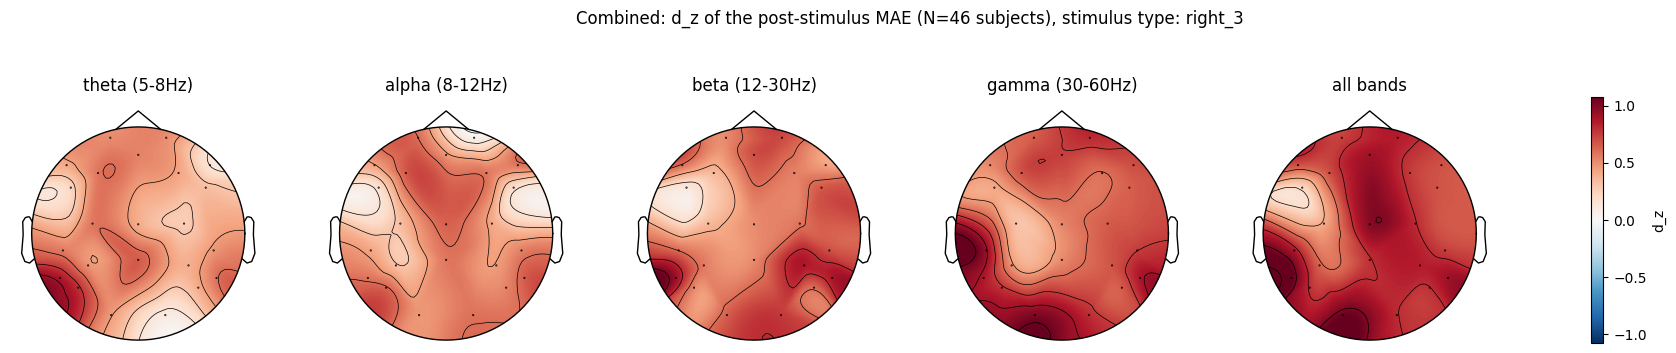

Combined: d_z of the post-stimulus MAE, d_z:
  theta (5-8Hz)    max: A1 +0.86, T5 +0.77, PZ +0.66   min: O2 +0.11, T2 +0.15, F7 +0.25
  alpha (8-12Hz)   max: F3 +0.67, A2 +0.65, CZ +0.64   min: FP2 +0.06, F8 +0.19, F7 +0.20
  beta (12-30Hz)   max: A1 +0.91, P4 +0.87, A2 +0.87   min: F7 +0.12, C3 +0.35, F3 +0.35
  gamma (30-60Hz)  max: O1 +1.00, T3 +0.91, A2 +0.87   min: C3 +0.31, F7 +0.42, P3 +0.48
  all bands        max: A1 +1.08, O1 +1.05, CZ +0.98   min: F7 +0.23, C3 +0.42, P3 +0.63


In [15]:
plot_session_contrasts("mae", "MAE", "d_z")

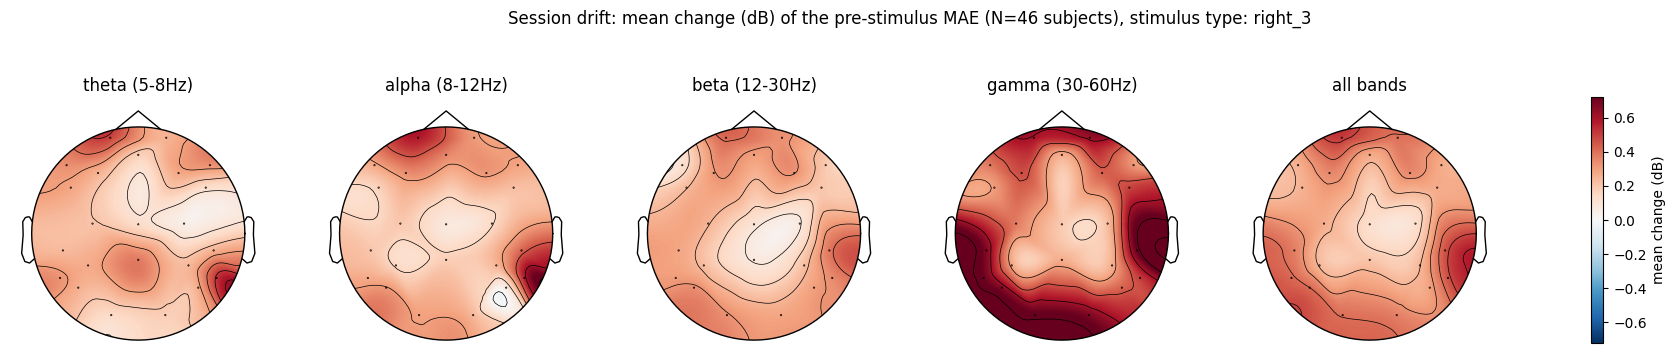

Session drift: mean change (dB) of the pre-stimulus MAE, mean change (dB):
  theta (5-8Hz)    max: A2 +0.51, FP1 +0.48, PZ +0.37  min: C4 +0.05, F8 +0.13, CZ +0.13
  alpha (8-12Hz)   max: A2 +0.57, FP1 +0.57, T4 +0.42  min: CZ +0.08, T6 +0.08, P3 +0.14
  beta (12-30Hz)   max: FP1 +0.41, T4 +0.38, A2 +0.34  min: C4 +0.07, PZ +0.07, CZ +0.10
  gamma (30-60Hz)  max: O1 +0.72, T4 +0.71, A1 +0.70   min: CZ +0.19, C4 +0.22, P4 +0.26
  all bands        max: FP1 +0.50, A2 +0.46, T4 +0.45  min: C4 +0.12, CZ +0.13, PZ +0.20


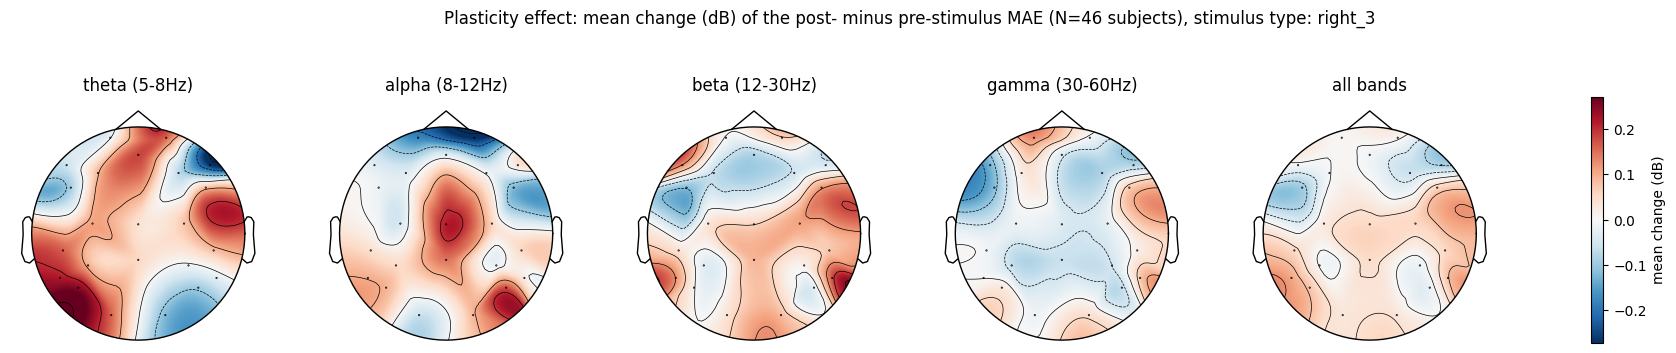

Plasticity effect: mean change (dB) of the post- minus pre-stimulus MAE, mean change (dB):
  theta (5-8Hz)    max: T5 +0.24, A1 +0.22, FZ +0.18   min: T2 -0.26, O2 -0.12, T6 -0.09
  alpha (8-12Hz)   max: CZ +0.22, T6 +0.17, PZ +0.15   min: FP2 -0.27, FP1 -0.18, F8 -0.12
  beta (12-30Hz)   max: A2 +0.17, A1 +0.12, T1 +0.12   min: F7 -0.12, FZ -0.08, F3 -0.06
  gamma (30-60Hz)  max: FP1 +0.12, A2 +0.07, F8 +0.07  min: T1 -0.12, F7 -0.11, F4 -0.08
  all bands        max: A1 +0.10, A2 +0.08, T5 +0.07   min: F7 -0.09, T2 -0.08, F4 -0.06


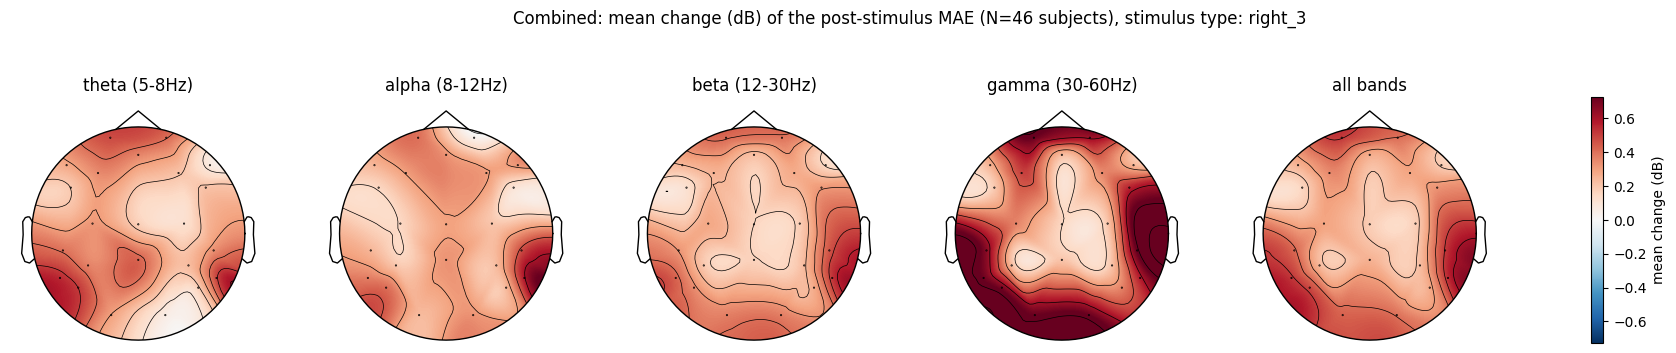

Combined: mean change (dB) of the post-stimulus MAE, mean change (dB):
  theta (5-8Hz)    max: A1 +0.54, T5 +0.50, A2 +0.49   min: O2 +0.06, T2 +0.07, C4 +0.12
  alpha (8-12Hz)   max: A2 +0.59, T4 +0.47, FP1 +0.40  min: FP2 +0.04, F8 +0.10, C3 +0.16
  beta (12-30Hz)   max: A2 +0.51, T4 +0.45, A1 +0.42   min: F7 +0.12, T2 +0.15, CZ +0.16
  gamma (30-60Hz)  max: T4 +0.73, FP1 +0.71, O1 +0.71  min: CZ +0.15, C4 +0.20, PZ +0.20
  all bands        max: A2 +0.54, A1 +0.51, T4 +0.51   min: F7 +0.16, C4 +0.18, CZ +0.18


In [16]:
plot_session_contrasts("mae", "MAE", "mean")

## Topomaps of the power change
The same three maps for the target power: the mean dB of the target over the window's bins, stored per trial and channel as
`signal_mean`, with interpolated channels left out. The windows are the same as for the errors, so an error change can be
compared with the power change at the same channels: the injection test showed that the dB error falls where power rises.
- **Session drift**: pre-stimulus power (`PRE_TARGET_WINDOW`), no stimulus on screen
- **Plasticity effect**: post- minus pre-stimulus power, the change of the stimulus response
- **Combined**: post-stimulus power, = drift + plasticity effect for the mean change

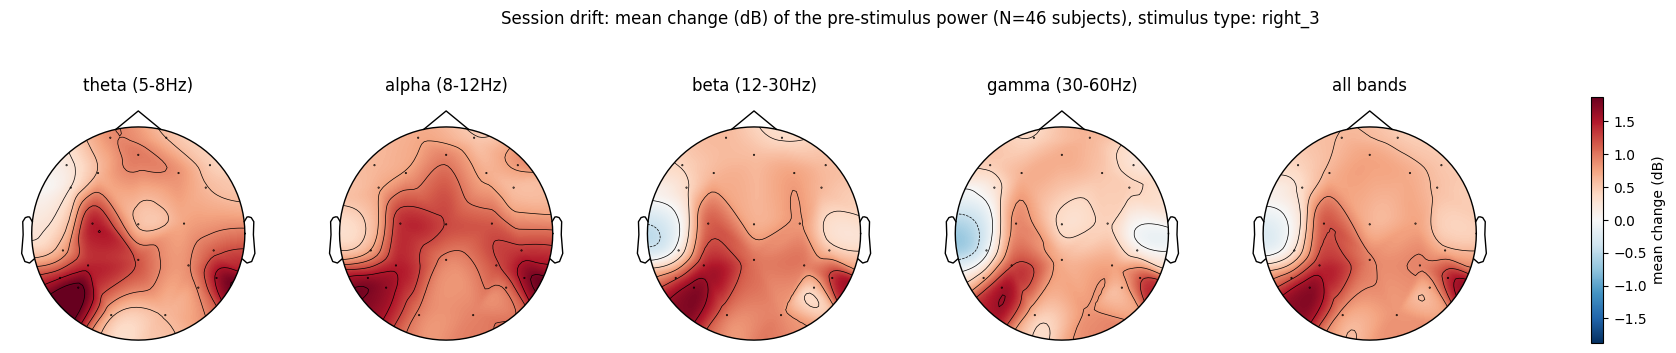

Session drift: mean change (dB) of the pre-stimulus power, mean change (dB):
  theta (5-8Hz)    max: T5 +1.87, A2 +1.55, A1 +1.49   min: T1 +0.21, F7 +0.31, T2 +0.47
  alpha (8-12Hz)   max: A2 +1.64, T5 +1.62, A1 +1.59   min: FP2 +0.52, F8 +0.58, T1 +0.62
  beta (12-30Hz)   max: T5 +1.70, P3 +1.41, A2 +1.30   min: T3 +0.16, F7 +0.37, FP2 +0.37
  gamma (30-60Hz)  max: T5 +1.53, P3 +1.19, A2 +1.13   min: T3 -0.09, T4 +0.15, F7 +0.26
  all bands        max: T5 +1.67, A2 +1.36, P3 +1.36   min: T3 +0.31, F7 +0.38, T1 +0.42


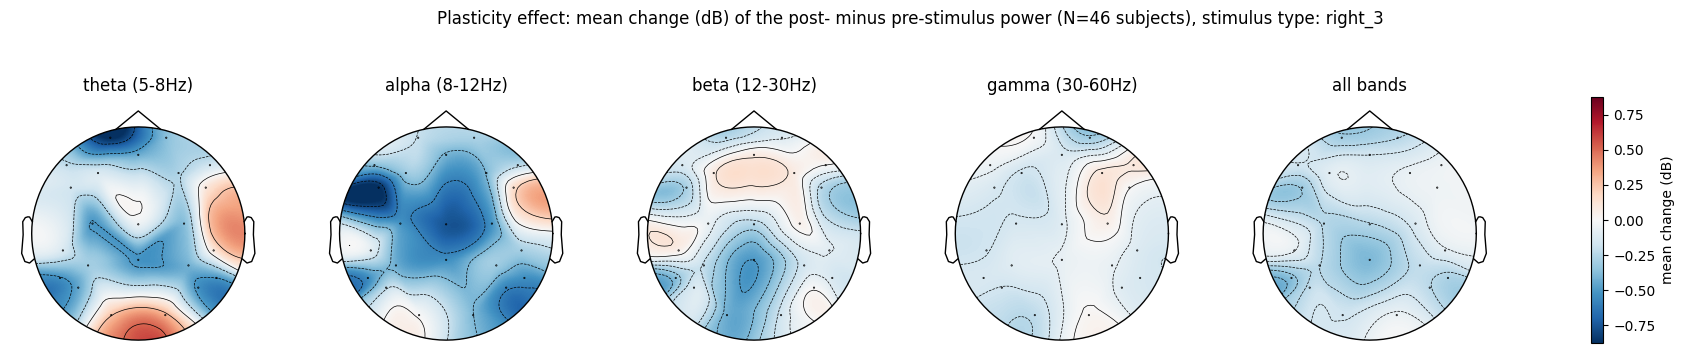

Plasticity effect: mean change (dB) of the post- minus pre-stimulus power, mean change (dB):
  theta (5-8Hz)    max: O2 +0.29, O1 +0.24, T4 +0.10   min: FP1 -0.88, T6 -0.53, PZ -0.53
  alpha (8-12Hz)   max: F8 +0.15, O1 -0.02, T3 -0.11   min: F7 -0.88, CZ -0.76, T6 -0.57
  beta (12-30Hz)   max: F3 +0.08, FZ +0.08, F4 +0.07   min: PZ -0.50, O1 -0.43, A1 -0.35
  gamma (30-60Hz)  max: F4 +0.11, T2 +0.09, C4 +0.05   min: FP2 -0.30, O1 -0.22, F3 -0.17
  all bands        max: F8 -0.04, T2 -0.04, F4 -0.06   min: PZ -0.39, A1 -0.35, F7 -0.31


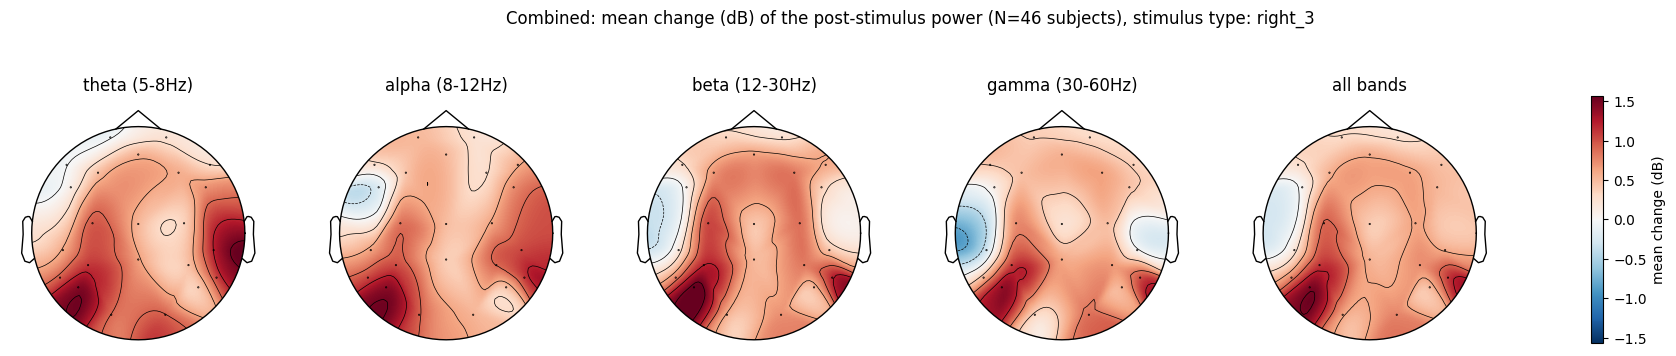

Combined: mean change (dB) of the post-stimulus power, mean change (dB):
  theta (5-8Hz)    max: T5 +1.43, T4 +1.21, P3 +1.11   min: FP1 -0.02, T1 -0.01, F7 +0.14
  alpha (8-12Hz)   max: T5 +1.40, A2 +1.11, A1 +1.06   min: F7 -0.17, FP2 +0.24, T1 +0.25
  beta (12-30Hz)   max: T5 +1.57, P3 +1.20, A2 +1.16   min: F7 +0.09, T3 +0.21, FP2 +0.26
  gamma (30-60Hz)  max: T5 +1.37, P3 +1.08, A2 +0.99   min: T3 -0.25, T4 +0.04, F7 +0.12
  all bands        max: T5 +1.46, P3 +1.12, A2 +1.08   min: F7 +0.07, T3 +0.23, T1 +0.25


In [17]:
plot_session_contrasts("signal_mean", "power", "mean")

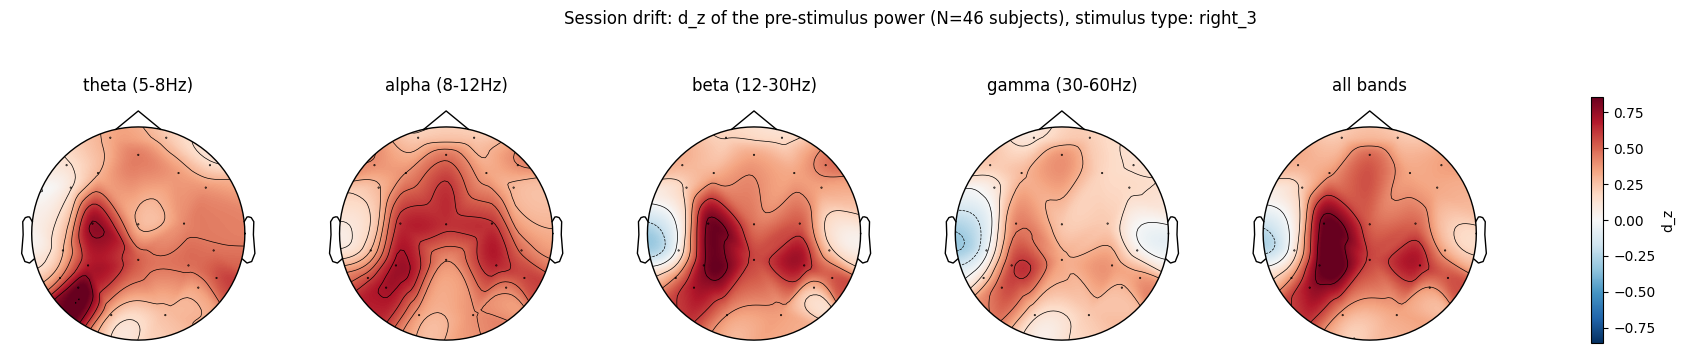

Session drift: d_z of the pre-stimulus power, d_z:
  theta (5-8Hz)    max: T5 +0.86, C3 +0.76, P3 +0.68   min: T1 +0.13, F7 +0.14, T2 +0.18
  alpha (8-12Hz)   max: P3 +0.72, T5 +0.72, P4 +0.65   min: FP1 +0.23, FP2 +0.23, F8 +0.28
  beta (12-30Hz)   max: C3 +0.82, P3 +0.79, T5 +0.70   min: T3 +0.07, FP2 +0.16, FP1 +0.20
  gamma (30-60Hz)  max: P3 +0.57, T5 +0.54, C3 +0.42   min: T3 -0.03, T4 +0.06, F7 +0.10
  all bands        max: P3 +0.85, C3 +0.85, T5 +0.74   min: T3 +0.13, F7 +0.23, FP1 +0.24


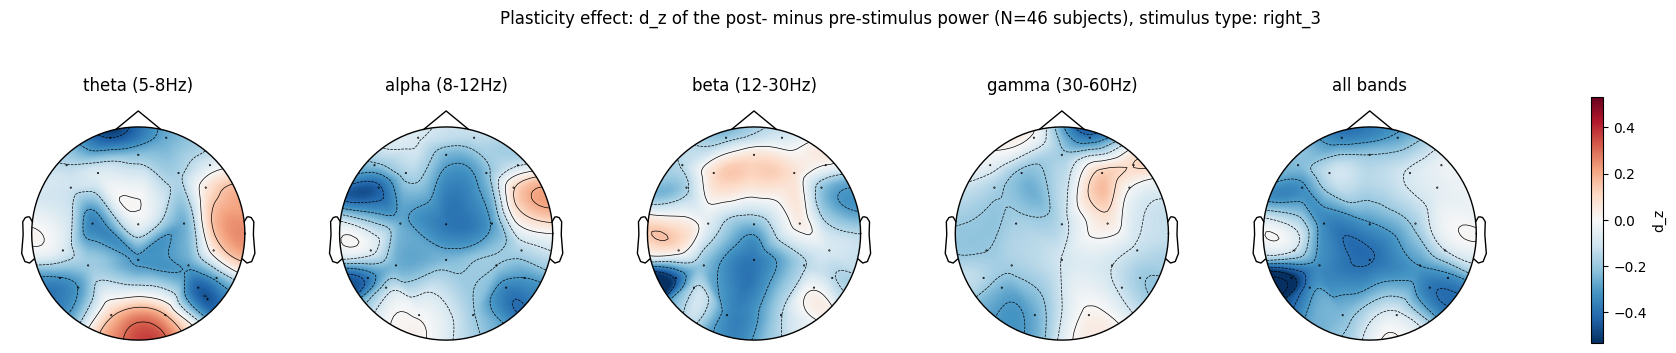

Plasticity effect: d_z of the post- minus pre-stimulus power, d_z:
  theta (5-8Hz)    max: O2 +0.15, O1 +0.13, F8 +0.06   min: FP1 -0.45, T6 -0.43, C3 -0.36
  alpha (8-12Hz)   max: F8 +0.09, O1 -0.01, T3 -0.06   min: F7 -0.42, CZ -0.38, A1 -0.36
  beta (12-30Hz)   max: F3 +0.10, FZ +0.08, F4 +0.08   min: A1 -0.43, PZ -0.38, O1 -0.34
  gamma (30-60Hz)  max: F4 +0.13, T2 +0.10, C4 +0.05   min: FP2 -0.37, O1 -0.26, T5 -0.25
  all bands        max: T2 -0.04, F8 -0.05, O2 -0.07   min: A1 -0.53, PZ -0.41, T6 -0.38


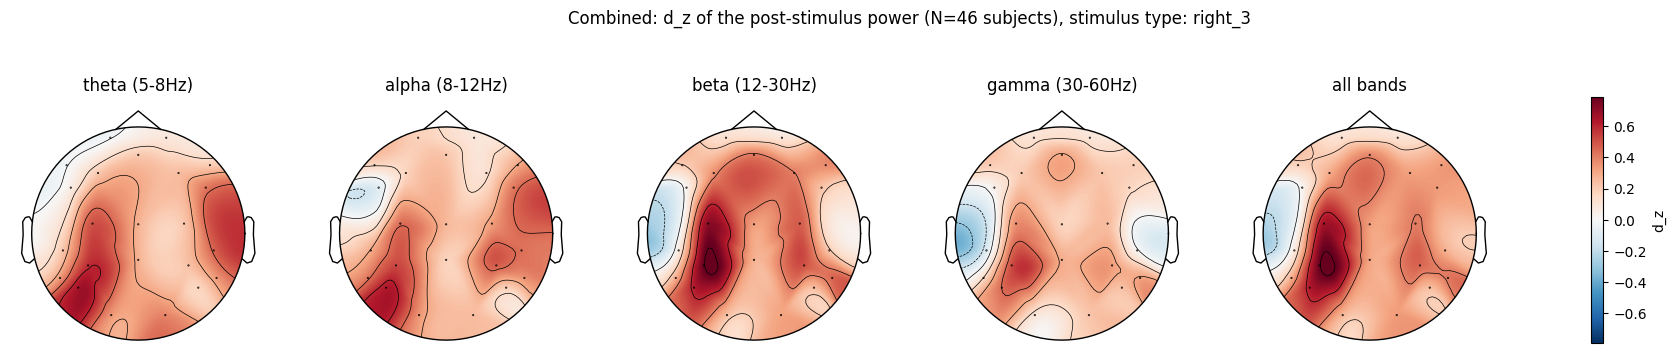

Combined: d_z of the post-stimulus power, d_z:
  theta (5-8Hz)    max: T5 +0.66, P3 +0.59, C3 +0.51   min: FP1 -0.01, T1 -0.00, F7 +0.08
  alpha (8-12Hz)   max: T5 +0.63, P3 +0.52, P4 +0.48   min: F7 -0.07, FP2 +0.09, F4 +0.13
  beta (12-30Hz)   max: P3 +0.79, C3 +0.71, T5 +0.63   min: F7 +0.04, T3 +0.09, FP2 +0.11
  gamma (30-60Hz)  max: P3 +0.52, T5 +0.45, C3 +0.37   min: T3 -0.09, T4 +0.01, F7 +0.05
  all bands        max: P3 +0.79, C3 +0.66, T5 +0.64   min: F7 +0.04, T3 +0.10, FP2 +0.12


In [18]:
plot_session_contrasts("signal_mean", "power", "d_z")

### Stimulus response per session
The post- minus pre-stimulus power of each session on its own (mean over subjects, dB), baseline and post-patching on the
same colour scale. The plasticity effect above is the difference of these two rows (post-patching - baseline), so these
maps show where the stimulus changes power at all and whether the response after patching is stronger, weaker or moved.

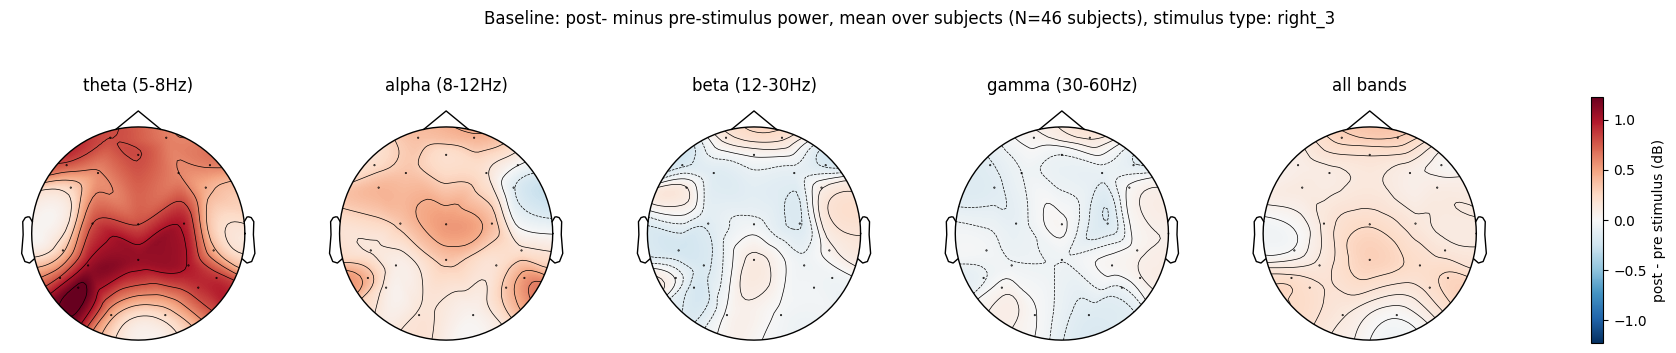

Baseline: post- minus pre-stimulus power, mean over subjects, post - pre stimulus (dB):
  theta (5-8Hz)    max: T5 +1.23, PZ +1.07, P3 +1.04   min: F7 +0.28, O2 +0.28, T3 +0.36
  alpha (8-12Hz)   max: CZ +0.53, A2 +0.52, FP2 +0.42  min: F8 -0.14, T2 +0.01, O2 +0.05
  beta (12-30Hz)   max: FP2 +0.18, FP1 +0.12, PZ +0.11 min: T3 -0.22, T5 -0.20, P3 -0.19
  gamma (30-60Hz)  max: FP2 +0.13, A2 +0.05, T4 +0.04  min: C4 -0.17, O2 -0.15, F7 -0.14
  all bands        max: FP2 +0.30, PZ +0.29, FP1 +0.27 min: T3 +0.01, O2 +0.01, T2 +0.03


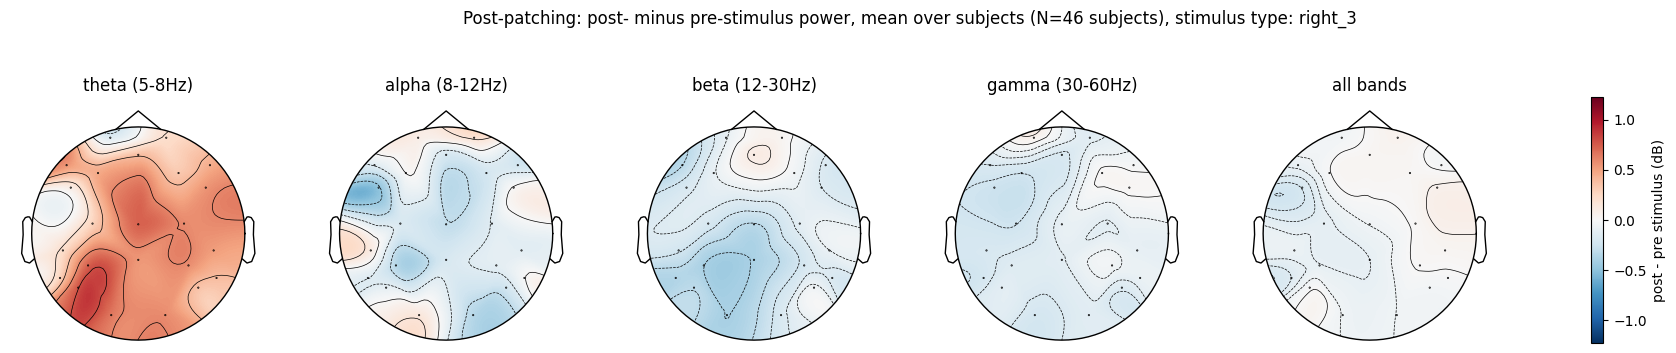

Post-patching: post- minus pre-stimulus power, mean over subjects, post - pre stimulus (dB):
  theta (5-8Hz)    max: T5 +0.79, P3 +0.74, CZ +0.72   min: FP1 -0.14, F7 +0.10, FP2 +0.22
  alpha (8-12Hz)   max: FP2 +0.17, O1 +0.12, T3 +0.09  min: F7 -0.47, P3 -0.36, O2 -0.34
  beta (12-30Hz)   max: FZ +0.10, FP2 +0.03, F4 -0.04  min: O1 -0.40, P3 -0.40, PZ -0.39
  gamma (30-60Hz)  max: FP1 +0.04, F8 +0.02, F4 +0.01  min: F7 -0.26, C3 -0.24, F3 -0.24
  all bands        max: F8 +0.06, FP2 +0.04, T4 +0.03  min: F7 -0.20, A1 -0.15, C3 -0.11


In [19]:
def session_response(session):
    """{band: (n_chans,) mean over subjects of the post- minus pre-stimulus power} of one session."""
    power = subject_means["signal_mean"][session]
    response = data_processor.subtract_channel_dicts(power["post"], power["pre"])
    band_names = next(iter(response["ch_0"].values())).keys()
    return {band: np.array([np.nanmean([values[band] for values in response[f"ch_{ch}"].values()]) for ch in range(settings.N_CHANNELS)])
            for band in band_names}


responses = {"Baseline": session_response("baseline"), "Post-patching": session_response("postpatch")}
max_val = max(np.nanmax(np.abs(vals)) for response in responses.values() for vals in response.values())  # one scale for both sessions
for (session, response), key in zip(responses.items(), ("baseline", "postpatch")):
    n_subjects = len(subject_means["signal_mean"][key]["post"]["ch_0"])
    draw_topomaps(response, f"{session}: post- minus pre-stimulus power, mean over subjects", f"signal_mean_stimulus_response_{key}",
                  "post - pre stimulus (dB)", max_val, n_subjects)


## Interpolation rates per channel
Interpolation rate of a channel: share of a subject's trials in which it was interpolated (for the whole recording or by
autoreject), read from the `interpolated` attribute every trial has in the inference files. The topomap shows the mean over
subjects of the change (post-patching - baseline) in percentage points, the table the rates of all trials of each session.
Interpolated channels are never scored, but a channel that is often interpolated tends to be noisy in its other trials too,
so a rate change can show up as an error change (see interpolation_error.py).

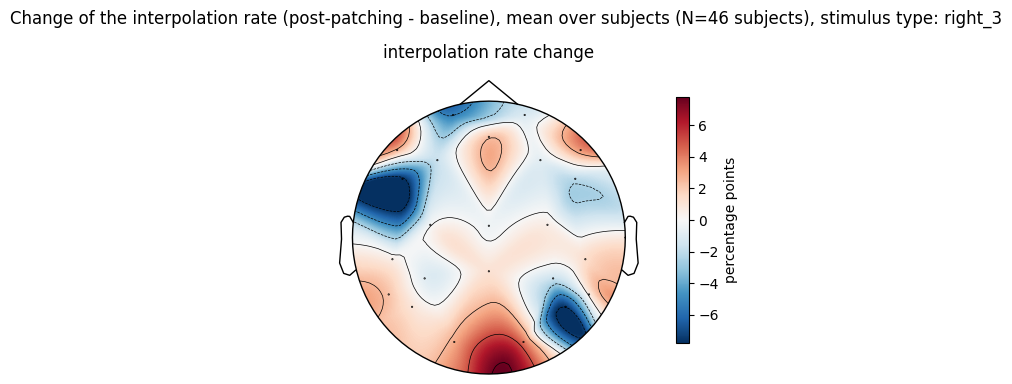

Change of the interpolation rate (post-patching - baseline), mean over subjects, percentage points:
  interpolation rate change max: O2 +4.18, T2 +3.16, O1 +2.90   min: F7 -7.79, T6 -7.48, FP1 -5.08

           baseline    post-patching
  1.  FP1  32.0 %      FP2  27.3 %
  2.  FP2  28.5 %       T4  26.8 %
  3.   T4  26.1 %      FP1  26.6 %
  4.   F7  25.8 %       F8  18.5 %
  5.   F8  20.0 %       F7  18.3 %
  6.   T3  15.1 %       T2  18.1 %
  7.   T2  14.5 %       O2  17.5 %
  8.   O1  14.3 %       O1  17.4 %
  9.   O2  12.9 %       T3  15.9 %
 10.   T6  11.8 %       FZ  13.2 %
 11.   T1  11.1 %       T1  13.1 %
 12.   CZ  10.3 %       PZ  11.5 %
 13.   PZ  10.1 %       CZ   9.9 %
 14.   FZ  10.0 %       F4   8.1 %
 15.   F4   9.0 %       A1   6.8 %
 16.   F3   6.7 %       A2   5.7 %
 17.   A2   5.7 %       T5   5.5 %
 18.   P4   5.1 %       F3   5.0 %
 19.   A1   5.0 %       T6   4.3 %
 20.   T5   4.5 %       P4   3.7 %
 21.   C3   3.8 %       C4   3.6 %
 22.   P3   3.2 %       C3  

In [20]:
def interpolation_rates(trials):
    """{subject: (n_chans,) share of the subject's trials with the channel interpolated} and the same share over all trials."""
    counts, n_trials = {}, {}
    for trial in trials:
        interpolated = trial.trial_data.parent.attrs["interpolated"]  # attribute of the trial group, shared by both patches
        counts.setdefault(trial.subject, np.zeros(settings.N_CHANNELS))[interpolated] += 1
        n_trials[trial.subject] = n_trials.get(trial.subject, 0) + 1
    overall = sum(counts.values()) / sum(n_trials.values())
    return {subject: counts[subject] / n_trials[subject] for subject in counts}, overall


b_rates, b_overall = interpolation_rates(baseline_merged)
p_rates, p_overall = interpolation_rates(postpatch_merged)
paired = [s for s in b_rates if s in p_rates]
rate_change = 100 * np.mean([p_rates[s] - b_rates[s] for s in paired], axis=0)  # percentage points
draw_topomaps({"interpolation rate change": rate_change}, "Change of the interpolation rate (post-patching - baseline), mean over subjects",
              "interpolation_rate_change", "percentage points", np.abs(rate_change).max(), len(paired))

# overall rates of every session, each column in descending order
b_order, p_order = np.argsort(-b_overall), np.argsort(-p_overall)
print(f"\n{'':4s} {'baseline':>14s}   {'post-patching':>14s}")
for rank, (b_ch, p_ch) in enumerate(zip(b_order, p_order), start=1):
    print(f"{rank:3d}. {CH_NAMES[b_ch]:>4s} {100 * b_overall[b_ch]:5.1f} %     {CH_NAMES[p_ch]:>4s} {100 * p_overall[p_ch]:5.1f} %")
print(f"mean {100 * b_overall.mean():9.1f} %     {100 * p_overall.mean():9.1f} %   ({len(baseline_merged)} / {len(postpatch_merged)} trials)")


## Lateralised visual response (contralateral - ipsilateral)
A stimulus in one visual field drives the opposite hemisphere first, whichever eye sees it. For every left and right stimulus
(`left_1..3`, `right_1..3`, all eccentricities) and every homologous occipito-parietal pair (O1/O2, P3/P4, T5/T6):
1. response = post- minus pre-stimulus power of the trial (`signal_mean`, analysis windows), per channel and band
2. lateralisation = response of the hemisphere opposite to the stimulus - response of the same-side hemisphere
3. subject mean over the trials (channels interpolated in a trial are left out), and the mean of the three pairs

Anything that affects both hemispheres alike (cap refit, fatigue, session-wide power or model changes) cancels in step 2, and
hemisphere differences that don't depend on the stimulus side cancel between left and right stimuli. The session change of the
lateralisation is therefore a cleaner test of a change in the visual response than the whole-head maps.
Subjects are grouped by the patched eye (STMD1-34: the dominant eye, from STMD35 on: the right eye); the left-dominant subjects
patched on the right eye are left out. Every eye projects to both hemispheres, so the eye groups test whether the effect differs
with the deprived eye, not a hemisphere-specific prediction. All subjects except `settings.EXCLUDED_SUBJECTS` are loaded here,
independent of the eye filters above.

In [21]:
import pandas as pd
from scipy.stats import ttest_1samp

LATERAL_CONDITIONS = [f"{side}_{ecc}" for side in ("left", "right") for ecc in (1, 2, 3)]
HEMISPHERE_PAIRS = [("O1", "O2"), ("P3", "P4"), ("T5", "T6")]  # (left hemisphere, right hemisphere)
PAIR_MEAN = "mean of pairs"
band_keys_lat = [*settings.FREQ_BANDS, data_processor.ALL_BANDS]


def patched_eye_groups():
    """{group: subjects} of the subjects patched on their dominant eye: STMD1-34 the dominant eye, from STMD35 on the right eye."""
    early = pd.read_csv(settings.DATA_ROOT / "eye_dominance.csv")
    late = pd.read_csv(settings.DATA_ROOT / "rightpatch_eye_dominance.csv")
    right = [*early.loc[early.eye_dominance == "right", "subject_id"], *late.loc[late.eye_dominance == "right", "subject_id"]]
    left = list(early.loc[early.eye_dominance == "left", "subject_id"])
    return {"right eye patched": right, "left eye patched": left}


def load_lateral_trials(session_file, stim_patch):
    """The lateral-stimulus trials of every fold's inference file of one session and patch."""
    trials = []
    for i in range(1, 7):
        trials.extend(io.load_inference_trials(settings.INFERENCE_DIR / model_name / str(i) / session_file, conditions=LATERAL_CONDITIONS,
                                               exclude_subjects=settings.EXCLUDED_SUBJECTS, window=time_window, stim_patch=stim_patch))
    return trials


def band_value(metrics, metric, band):
    """The metric of the whole band range for "all bands", otherwise its value in band."""
    return getattr(metrics, metric) if band == data_processor.ALL_BANDS else getattr(metrics, f"{metric}_bandwise")[band]


def subject_lateralisation(post_trials, pre_trials, metric="signal_mean"):
    """
    {subject: {band: {pair or PAIR_MEAN: value}}}: subject mean over the lateral trials of contralateral - ipsilateral of the
    post- minus pre-stimulus metric. Trials are paired by (subject, condition, id); channels interpolated in a trial are NaN and left out.
    """
    pre_by_key = {(t.subject, t.condition, t.idx): t for t in pre_trials}
    per_trial = {}  # {subject: {band: {pair: [values]}}}
    for post in post_trials:
        pre = pre_by_key.get((post.subject, post.condition, post.idx))
        if pre is None:
            continue
        stimulus_left = post.condition.startswith("left")
        subject_values = per_trial.setdefault(post.subject, {band: {pair: [] for pair in HEMISPHERE_PAIRS} for band in band_keys_lat})
        for band in band_keys_lat:
            for pair in HEMISPHERE_PAIRS:
                left_ch, right_ch = (f"ch_{CH_NAMES.index(name)}" for name in pair)
                response = {ch: band_value(post.channel_metrics[ch], metric, band) - band_value(pre.channel_metrics[ch], metric, band)
                            for ch in (left_ch, right_ch)}
                contra, ipsi = (right_ch, left_ch) if stimulus_left else (left_ch, right_ch)
                subject_values[band][pair].append(response[contra] - response[ipsi])
    result = {}
    for subject, bands_values in per_trial.items():
        result[subject] = {}
        for band, pair_values in bands_values.items():
            pair_means = {pair: np.nanmean(values) for pair, values in pair_values.items()}
            result[subject][band] = {**pair_means, PAIR_MEAN: np.nanmean(list(pair_means.values()))}
    return result


lateral = {session: subject_lateralisation(load_lateral_trials(f"{session}_reconstruction.h5", "post"),
                                           load_lateral_trials(f"{session}_reconstruction.h5", "pre"))
           for session in ("baseline", "postpatch")}


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: left_1, left_2, left_3, right_1, right_2, right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: left_1, left_2, left_3, right_1, right_2, right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: left_1, left_2, left_3, right_1, right_2, right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: left_1, left_2, left_3, right_1, right_2, right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: left_1, left_2, left_3, right_1, right_2, right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: left_1, left_2, left_3, right_1, right_2, right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filterin

C:\Users\Gábor\AppData\Local\Temp\ipykernel_23332\2700966521.py:57: RuntimeWarning: Mean of empty slice
  pair_means = {pair: np.nanmean(values) for pair, values in pair_values.items()}


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: left_1, left_2, left_3, right_1, right_2, right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: left_1, left_2, left_3, right_1, right_2, right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: left_1, left_2, left_3, right_1, right_2, right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: left_1, left_2, left_3, right_1, right_2, right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: left_1, left_2, left_3, right_1, right_2, right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: left_1, left_2, left_3, right_1, right_2, right_3
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filterin


=== right eye patched (N=40): contralateral - ipsilateral post- minus pre-stimulus power (dB), one-sample p per session, paired p of the change


,band,pair,n,baseline,baseline_sem,baseline_p,postpatch,postpatch_sem,postpatch_p,change,change_d_z,change_p
0,theta (5-8Hz),O1/O2,39,0.247,0.082,0.005,0.143,0.138,0.305,-0.104,-0.119,0.463
1,theta (5-8Hz),P3/P4,40,0.282,0.119,0.022,0.315,0.112,0.007,0.033,0.033,0.834
2,theta (5-8Hz),T5/T6,40,0.381,0.104,0.001,0.357,0.121,0.005,-0.024,-0.025,0.875
3,theta (5-8Hz),mean of pairs,40,0.306,0.080,0.000,0.288,0.093,0.004,-0.018,-0.026,0.868
4,alpha (8-12Hz),O1/O2,39,0.028,0.125,0.827,-0.055,0.237,0.817,-0.083,-0.050,0.755
5,alpha (8-12Hz),P3/P4,40,-0.032,0.091,0.725,-0.053,0.102,0.605,-0.021,-0.026,0.872
6,alpha (8-12Hz),T5/T6,40,-0.053,0.129,0.682,0.085,0.096,0.381,0.138,0.159,0.322
7,alpha (8-12Hz),mean of pairs,40,-0.032,0.087,0.710,0.022,0.101,0.831,0.054,0.066,0.679
8,beta (12-30Hz),O1/O2,39,-0.008,0.058,0.890,-0.102,0.080,0.205,-0.094,-0.158,0.330
9,beta (12-30Hz),P3/P4,40,0.000,0.067,0.994,-0.059,0.044,0.186,-0.060,-0.118,0.459


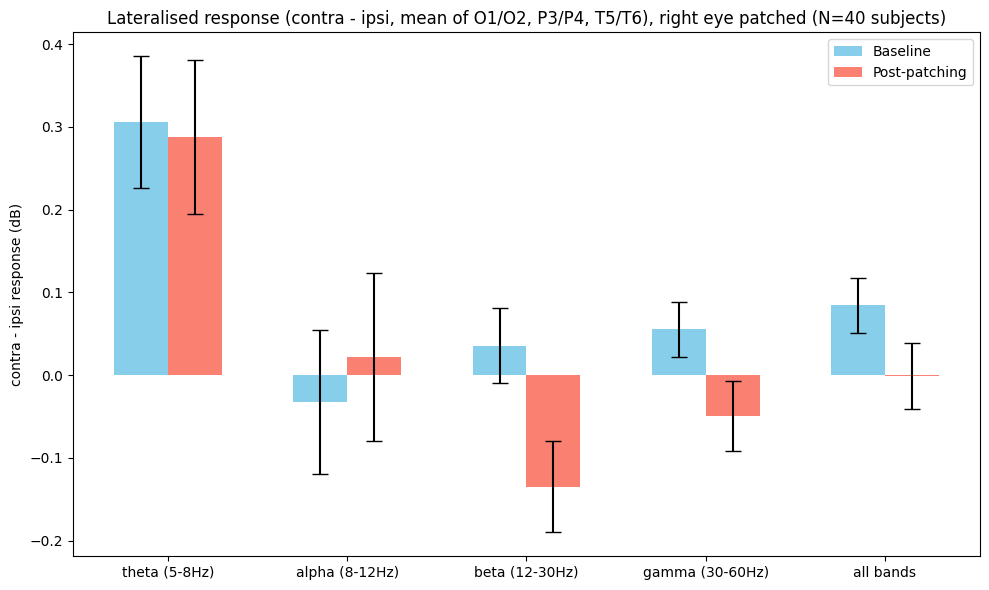


=== left eye patched (N=5): contralateral - ipsilateral post- minus pre-stimulus power (dB), one-sample p per session, paired p of the change


,band,pair,n,baseline,baseline_sem,baseline_p,postpatch,postpatch_sem,postpatch_p,change,change_d_z,change_p
0,theta (5-8Hz),O1/O2,5,-0.190,0.359,0.624,-0.269,0.200,0.249,-0.079,-0.140,0.771
1,theta (5-8Hz),P3/P4,5,-0.207,0.352,0.588,-0.274,0.324,0.445,-0.067,-0.107,0.822
2,theta (5-8Hz),T5/T6,5,-0.639,0.529,0.293,-0.361,0.332,0.338,0.278,0.280,0.565
3,theta (5-8Hz),mean of pairs,5,-0.346,0.403,0.440,-0.301,0.257,0.306,0.044,0.069,0.885
4,alpha (8-12Hz),O1/O2,5,0.123,0.283,0.686,-0.186,0.187,0.375,-0.309,-0.426,0.394
5,alpha (8-12Hz),P3/P4,5,-0.241,0.229,0.351,-0.206,0.179,0.314,0.036,0.047,0.921
6,alpha (8-12Hz),T5/T6,5,-0.584,0.311,0.134,-0.218,0.197,0.331,0.365,0.458,0.364
7,alpha (8-12Hz),mean of pairs,5,-0.234,0.215,0.338,-0.203,0.163,0.281,0.031,0.052,0.913
8,beta (12-30Hz),O1/O2,5,-0.112,0.146,0.487,0.054,0.256,0.843,0.166,0.240,0.620
9,beta (12-30Hz),P3/P4,5,-0.167,0.109,0.200,-0.061,0.109,0.606,0.106,0.219,0.650


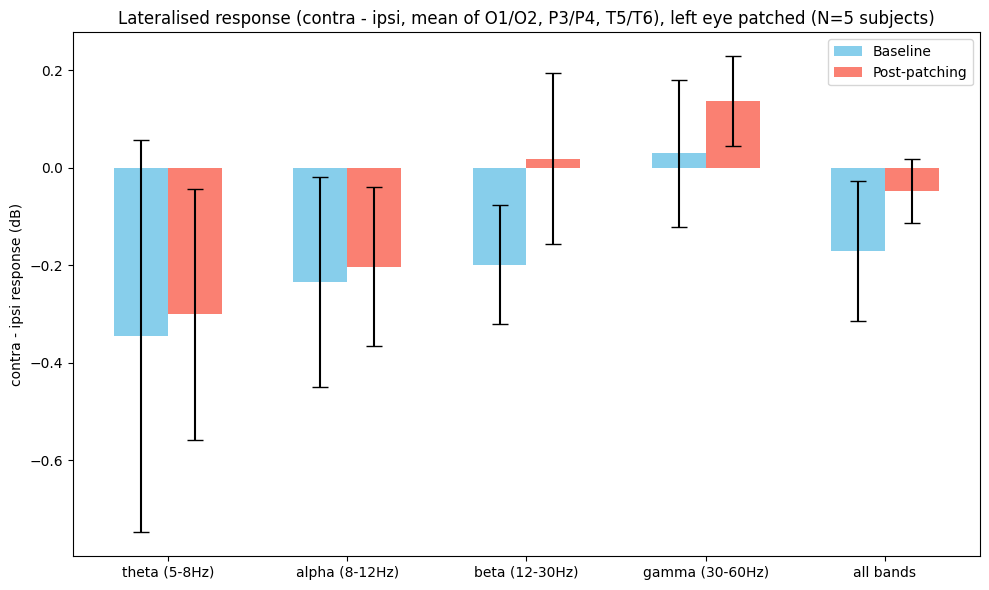

In [22]:
def lateralisation_stats(subjects, metric_label="power"):
    """Per band and pair: lateralisation per session (mean, SEM, one-sample t-test) and its session change (d_z, paired t-test)."""
    subjects = [s for s in subjects if s in lateral["baseline"] and s in lateral["postpatch"]]
    rows = []
    for band in band_keys_lat:
        for pair in [*HEMISPHERE_PAIRS, PAIR_MEAN]:
            b = np.array([lateral["baseline"][s][band][pair] for s in subjects])
            p = np.array([lateral["postpatch"][s][band][pair] for s in subjects])
            ok = np.isfinite(b) & np.isfinite(p)
            b, p = b[ok], p[ok]
            d = p - b
            rows.append({"band": band, "pair": pair if pair == PAIR_MEAN else "/".join(pair), "n": ok.sum(),
                         "baseline": b.mean(), "baseline_sem": sem(b), "baseline_p": ttest_1samp(b, 0).pvalue,
                         "postpatch": p.mean(), "postpatch_sem": sem(p), "postpatch_p": ttest_1samp(p, 0).pvalue,
                         "change": d.mean(), "change_d_z": d.mean() / d.std(ddof=1), "change_p": ttest_rel(p, b).pvalue})
    return pd.DataFrame(rows)


for group, group_subjects in patched_eye_groups().items():
    table = lateralisation_stats(group_subjects)
    n = int(table["n"].max())
    print(f"\n=== {group} (N={n}): contralateral - ipsilateral post- minus pre-stimulus power (dB), one-sample p per session, paired p of the change")
    display(table.round(3))
    means = table[table.pair == PAIR_MEAN]
    fig, ax = plotting.plot_grouped_bar(x_text=list(means.band), width=0.3, means=[means.baseline, means.postpatch],
                                        sems=[means.baseline_sem, means.postpatch_sem], labels=["Baseline", "Post-patching"],
                                        title=f"Lateralised response (contra - ipsi, mean of O1/O2, P3/P4, T5/T6), {group}",
                                        y_label="contra - ipsi response (dB)", n_text=f"N={n} subjects")
    plotting.save_button(fig, save_dir=plot_root / "lateralisation", default_name=f"lateralisation_{group.replace(' ', '_')}_{an_suffix}")


## plotting bandwise amplitude changes pre- and post-patching

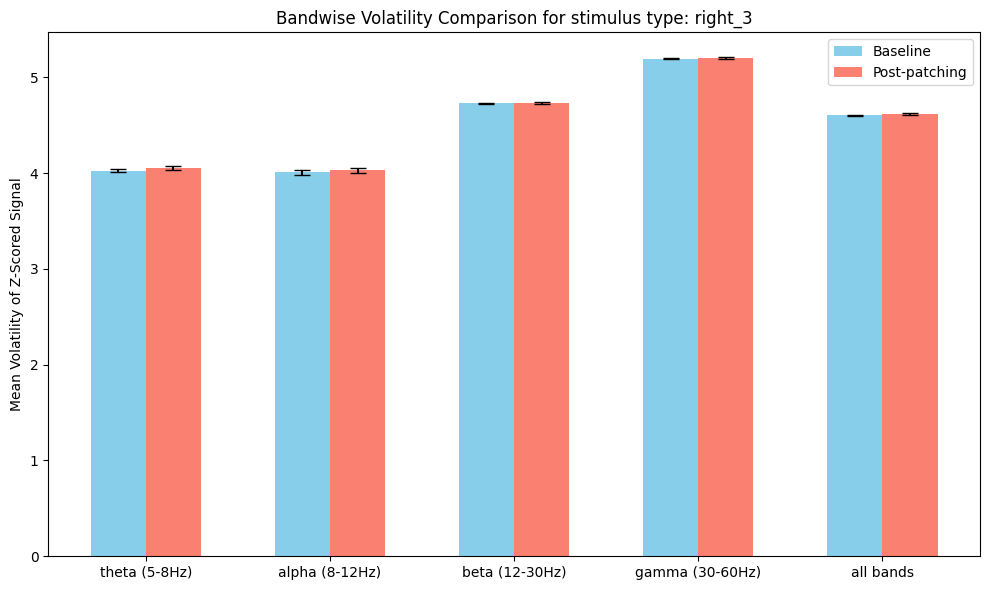

In [23]:
ampl_bw_b, sem_bw_b= data_processor.get_subjectwise_metric_mean(baseline_merged, bands=bands, metric_name="signal_volatility_bandwise")
ampl_bw_p, sem_bw_p = data_processor.get_subjectwise_metric_mean(postpatch_merged, bands=bands, metric_name="signal_volatility_bandwise")



x_text = list(ampl_bw_b.keys())



fig, ax = plt.subplots(figsize=(10, 6))
width = 0.3
x = np.arange(len(x_text))
title = f'Bandwise Volatility Comparison for stimulus type: {", ".join(conditions)}'

ax.bar(x - width / 2, ampl_bw_b.values(), width=width, yerr=sem_bw_b.values(), label='Baseline', color='skyblue', ecolor='black', capsize=6)
ax.bar(x + width / 2, ampl_bw_p.values(), width=width, yerr=sem_bw_p.values(), label='Post-patching', color='salmon', ecolor='black', capsize=6)
ax.set_xticks(x)
ax.set_xticklabels(x_text)

# Formatting
ax.set_ylabel('Mean Volatility of Z-Scored Signal')
ax.set_title(title)
ax.legend()

plotting.save_button(fig, save_dir=plot_root / "bandwise_volatility", default_name=f"bw_vols_{an_suffix}_{excl_suffix}")

plt.tight_layout()
plt.show()

### Paired tests of the volatility change
Per band: change of the subject-mean volatility (post - baseline) in % of the baseline mean, Cohen's d_z, paired t-test, Wilcoxon signed-rank test and the number of subjects whose volatility increased.

In [24]:
b_vol_means, _ = data_processor.calc_subjectwise_metric_stats(baseline_merged, bands, "signal_volatility")
p_vol_means, _ = data_processor.calc_subjectwise_metric_stats(postpatch_merged, bands, "signal_volatility")
subjects = [s for s in b_vol_means if s in p_vol_means]

print(f"Volatility change after patching ({time_window} window, N={len(subjects)} subjects)")
print(f"{'band':16s} {'change':>8s} {'d_z':>6s} {'t-test p':>9s} {'Wilcoxon p':>11s} {'increased':>10s}")
for band in [*bands, "all bands"]:
    pre = np.array([b_vol_means[s][band] for s in subjects])
    post = np.array([p_vol_means[s][band] for s in subjects])
    diffs = post - pre
    print(f"{band:16s} {100 * diffs.mean() / pre.mean():+7.2f}% {diffs.mean() / diffs.std(ddof=1):+6.2f} "
          f"{ttest_rel(post, pre).pvalue:9.3f} {wilcoxon(diffs).pvalue:11.3f} {np.sum(diffs > 0):5d}/{len(diffs)}")


Volatility change after patching (analysis window, N=46 subjects)
band               change    d_z  t-test p  Wilcoxon p  increased
theta (5-8Hz)      +0.66%  +0.19     0.204       0.133    27/46
alpha (8-12Hz)     +0.55%  +0.15     0.316       0.362    28/46
beta (12-30Hz)     +0.18%  +0.13     0.372       0.386    24/46
gamma (30-60Hz)    +0.10%  +0.08     0.573       0.829    22/46
all bands          +0.29%  +0.26     0.087       0.058    26/46


## Plotting NMAE distribution of pre and post-patching trials

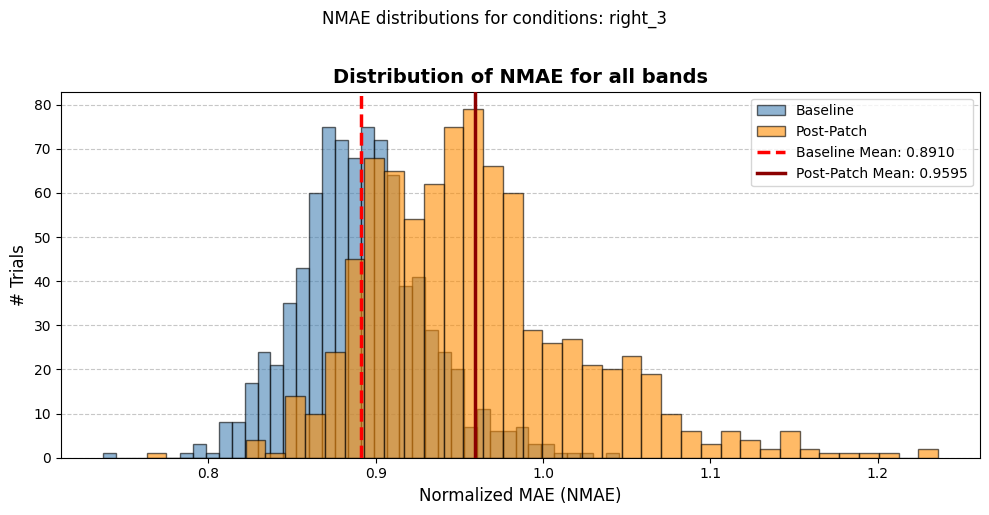

In [25]:
pre_nmaes = data_processor.extract_metric(baseline_merged, "nmae")
post_nmaes = data_processor.extract_metric(postpatch_merged, "nmae")

save_dir = plot_root / "nmae_dist_comparison"
plotting.distribution_viewer({"all bands": pre_nmaes}, {"all bands": post_nmaes}, title=f'NMAE distributions for conditions: {", ".join(conditions)}', save_dir=save_dir, save_name = f"nmae_dist_all_bands_{an_suffix}_{excl_suffix}")



## Plotting bandwise NMAE distribution of pre and post-patching trials

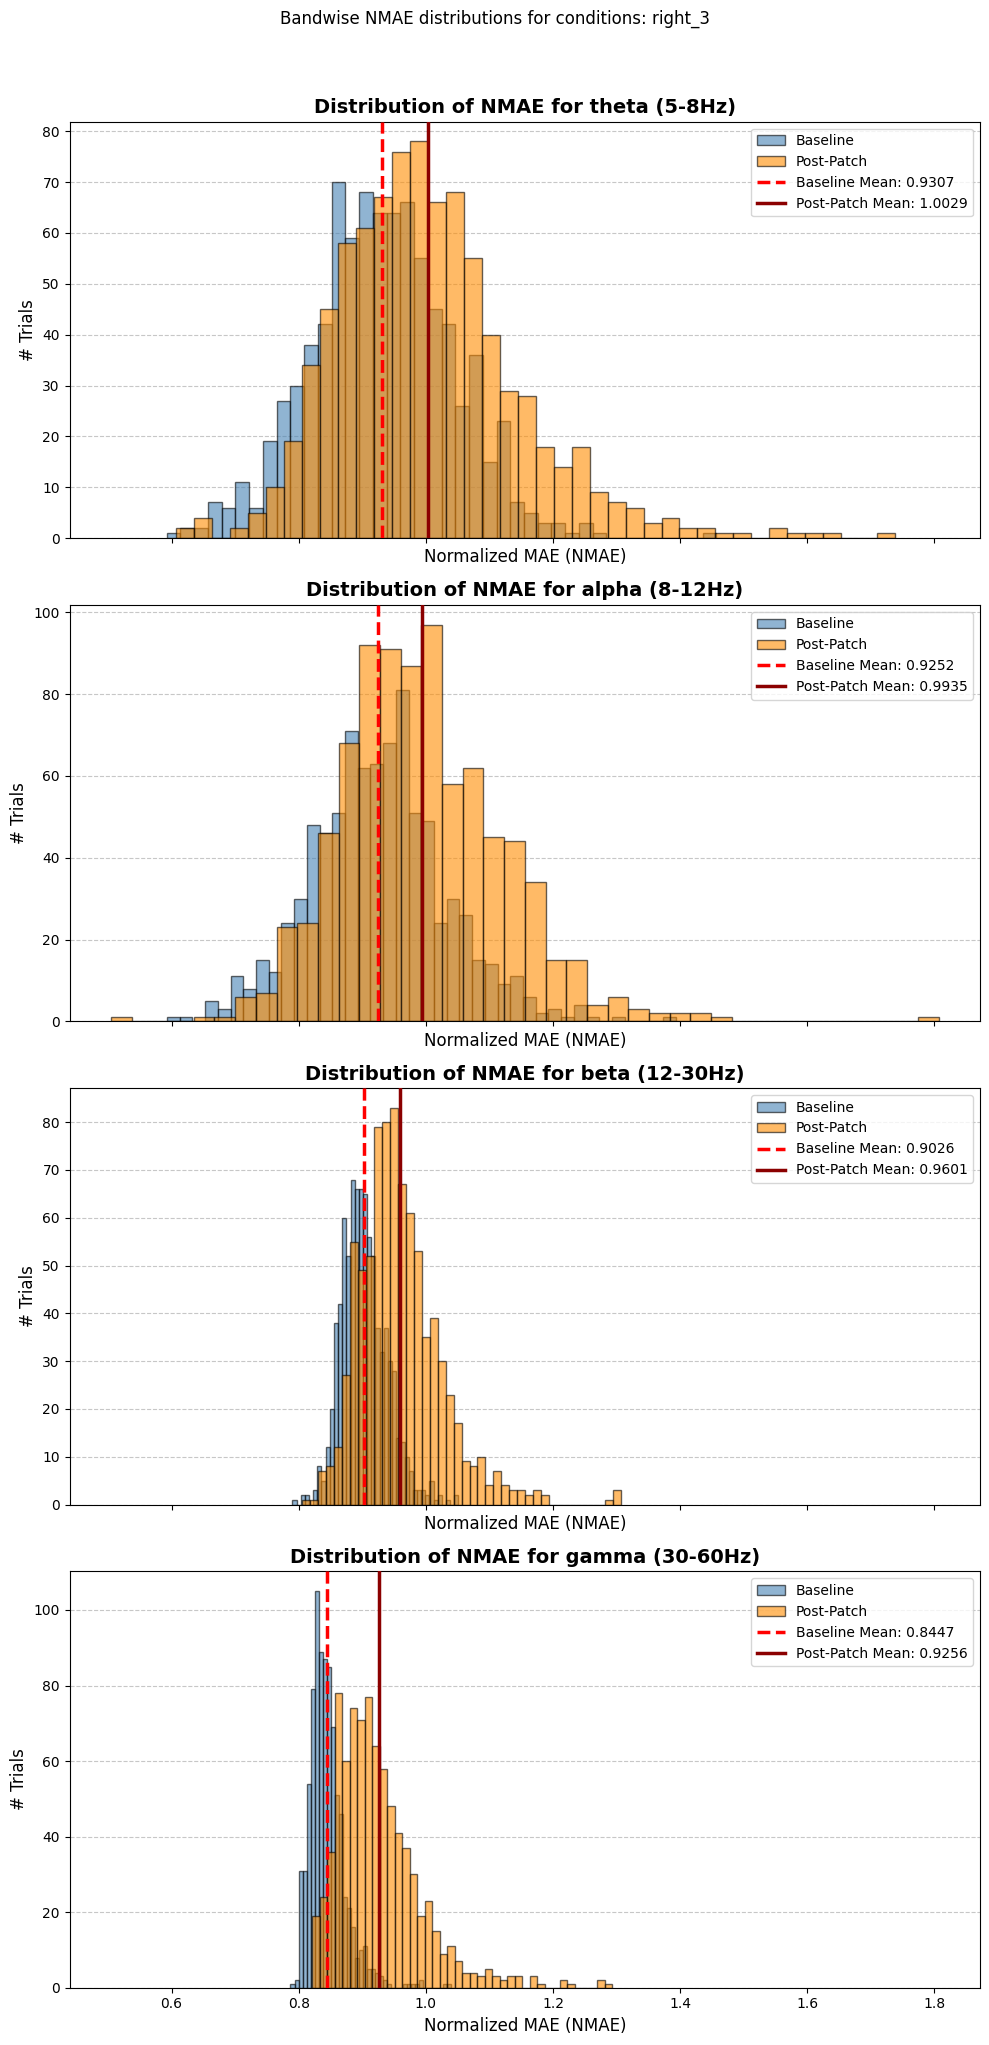

In [26]:
pre_nmaes_bw = data_processor.extract_metric(baseline_merged, "nmae_bandwise", bandwise=True, bands=settings.FREQ_BANDS)
post_nmaes_bw = data_processor.extract_metric(postpatch_merged, "nmae_bandwise", bandwise=True, bands=settings.FREQ_BANDS)

save_dir = plot_root / "nmae_dist_comparison"
plotting.distribution_viewer(pre_nmaes_bw, post_nmaes_bw, title=f'Bandwise NMAE distributions for conditions: {", ".join(conditions)}', save_dir=save_dir, save_name = f"nmae_dist_bandwise_{an_suffix}_{excl_suffix}")



## Correlation of signal power and model error (MAE vs corrected MAE)
Trials of both sessions and all subjects are pooled, power is the trial's mean dB of the target (`signal_mean`).
The pooled slope mixes two relations: power changes within a subject and session (what `fill_corrected_maes` fits and removes)
and power differences between subjects and sessions (which it doesn't touch). The corrected MAE is therefore not flat here:
its pooled slope is the raw pooled slope minus the within-subject slope, i.e. what remains of the between-subject relation.

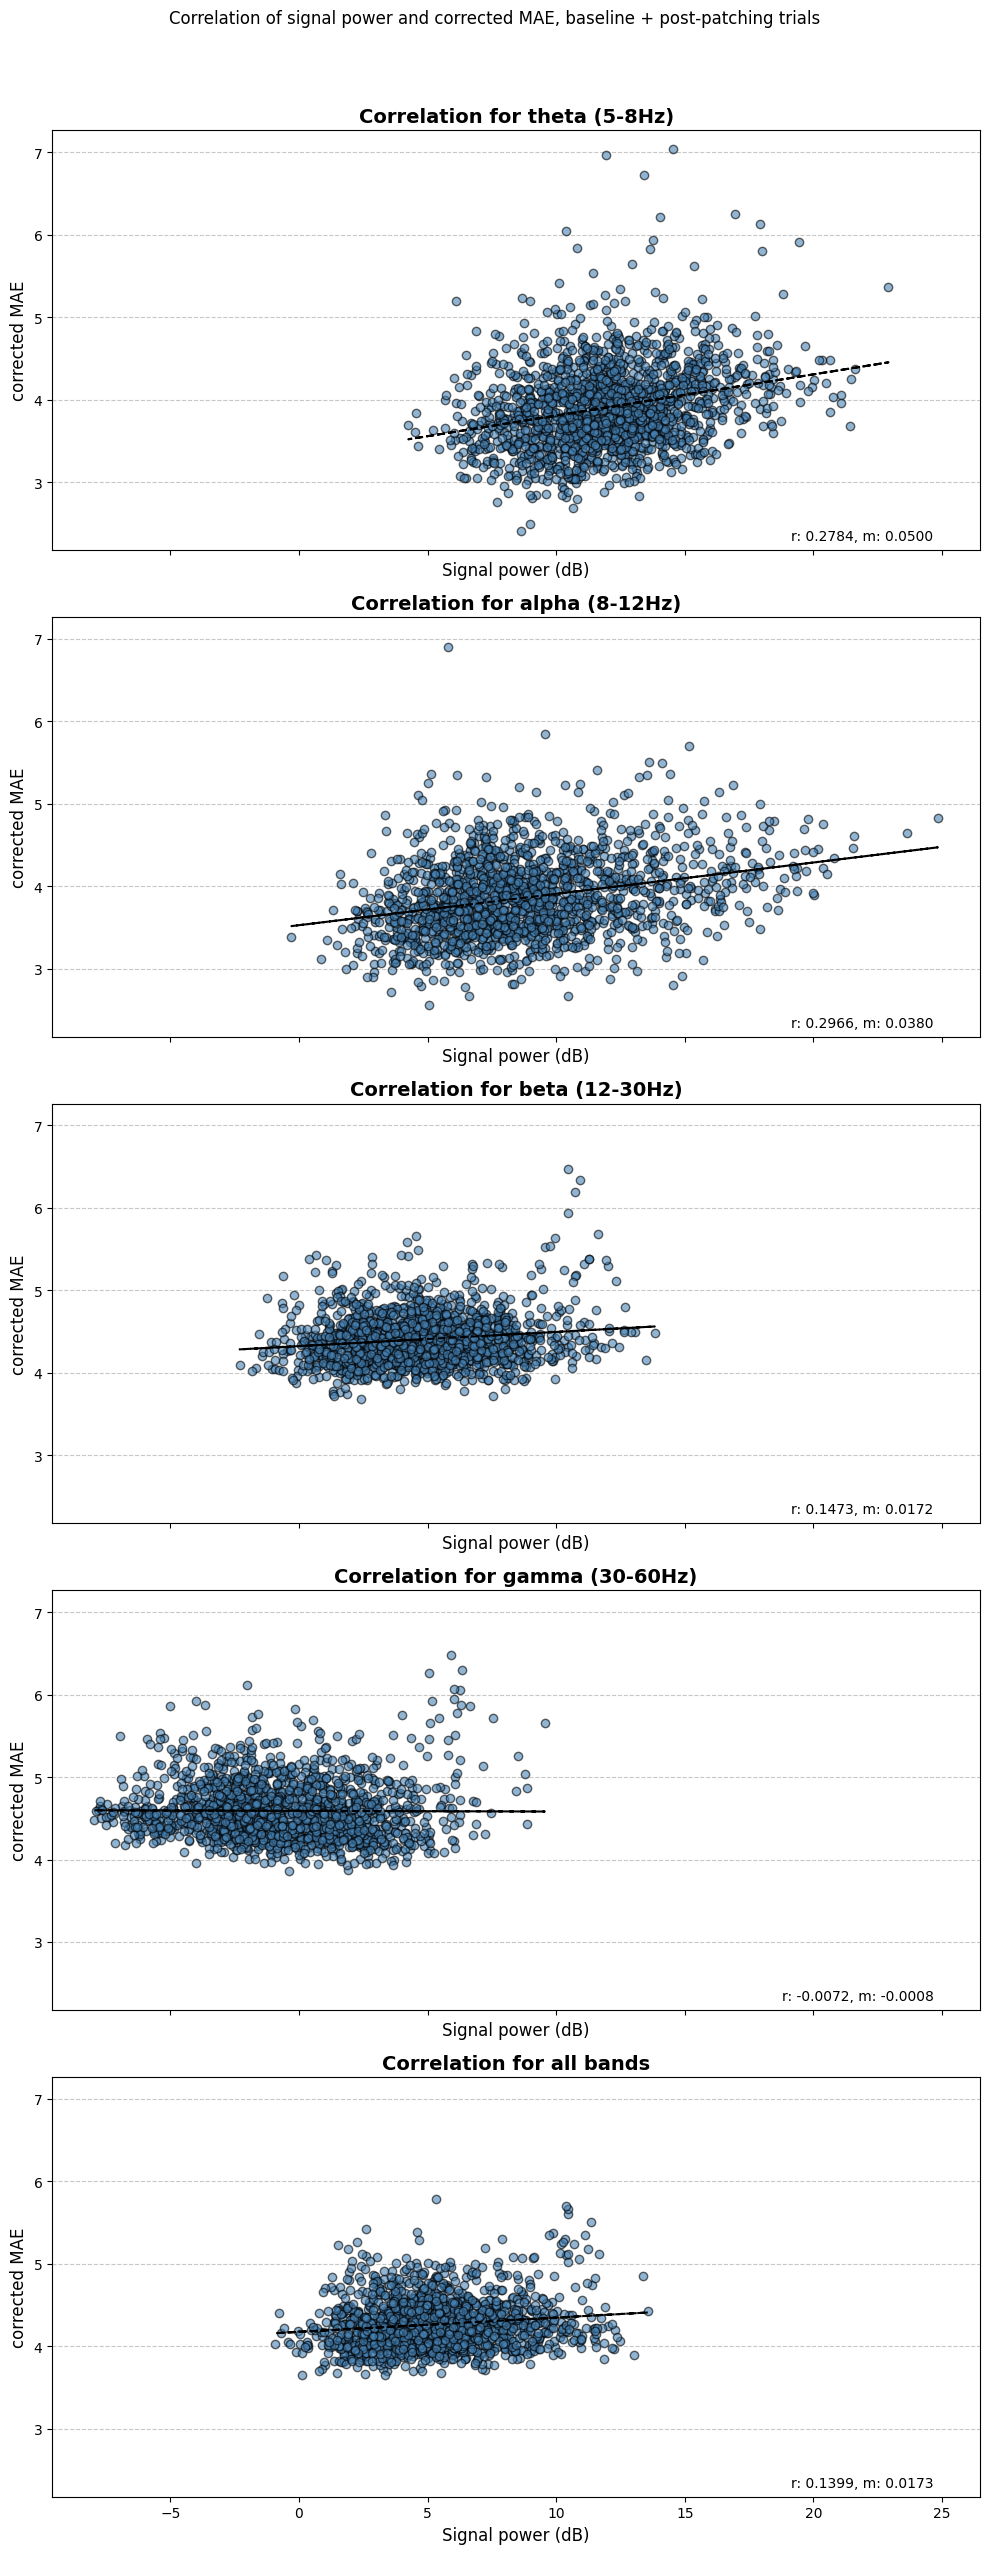

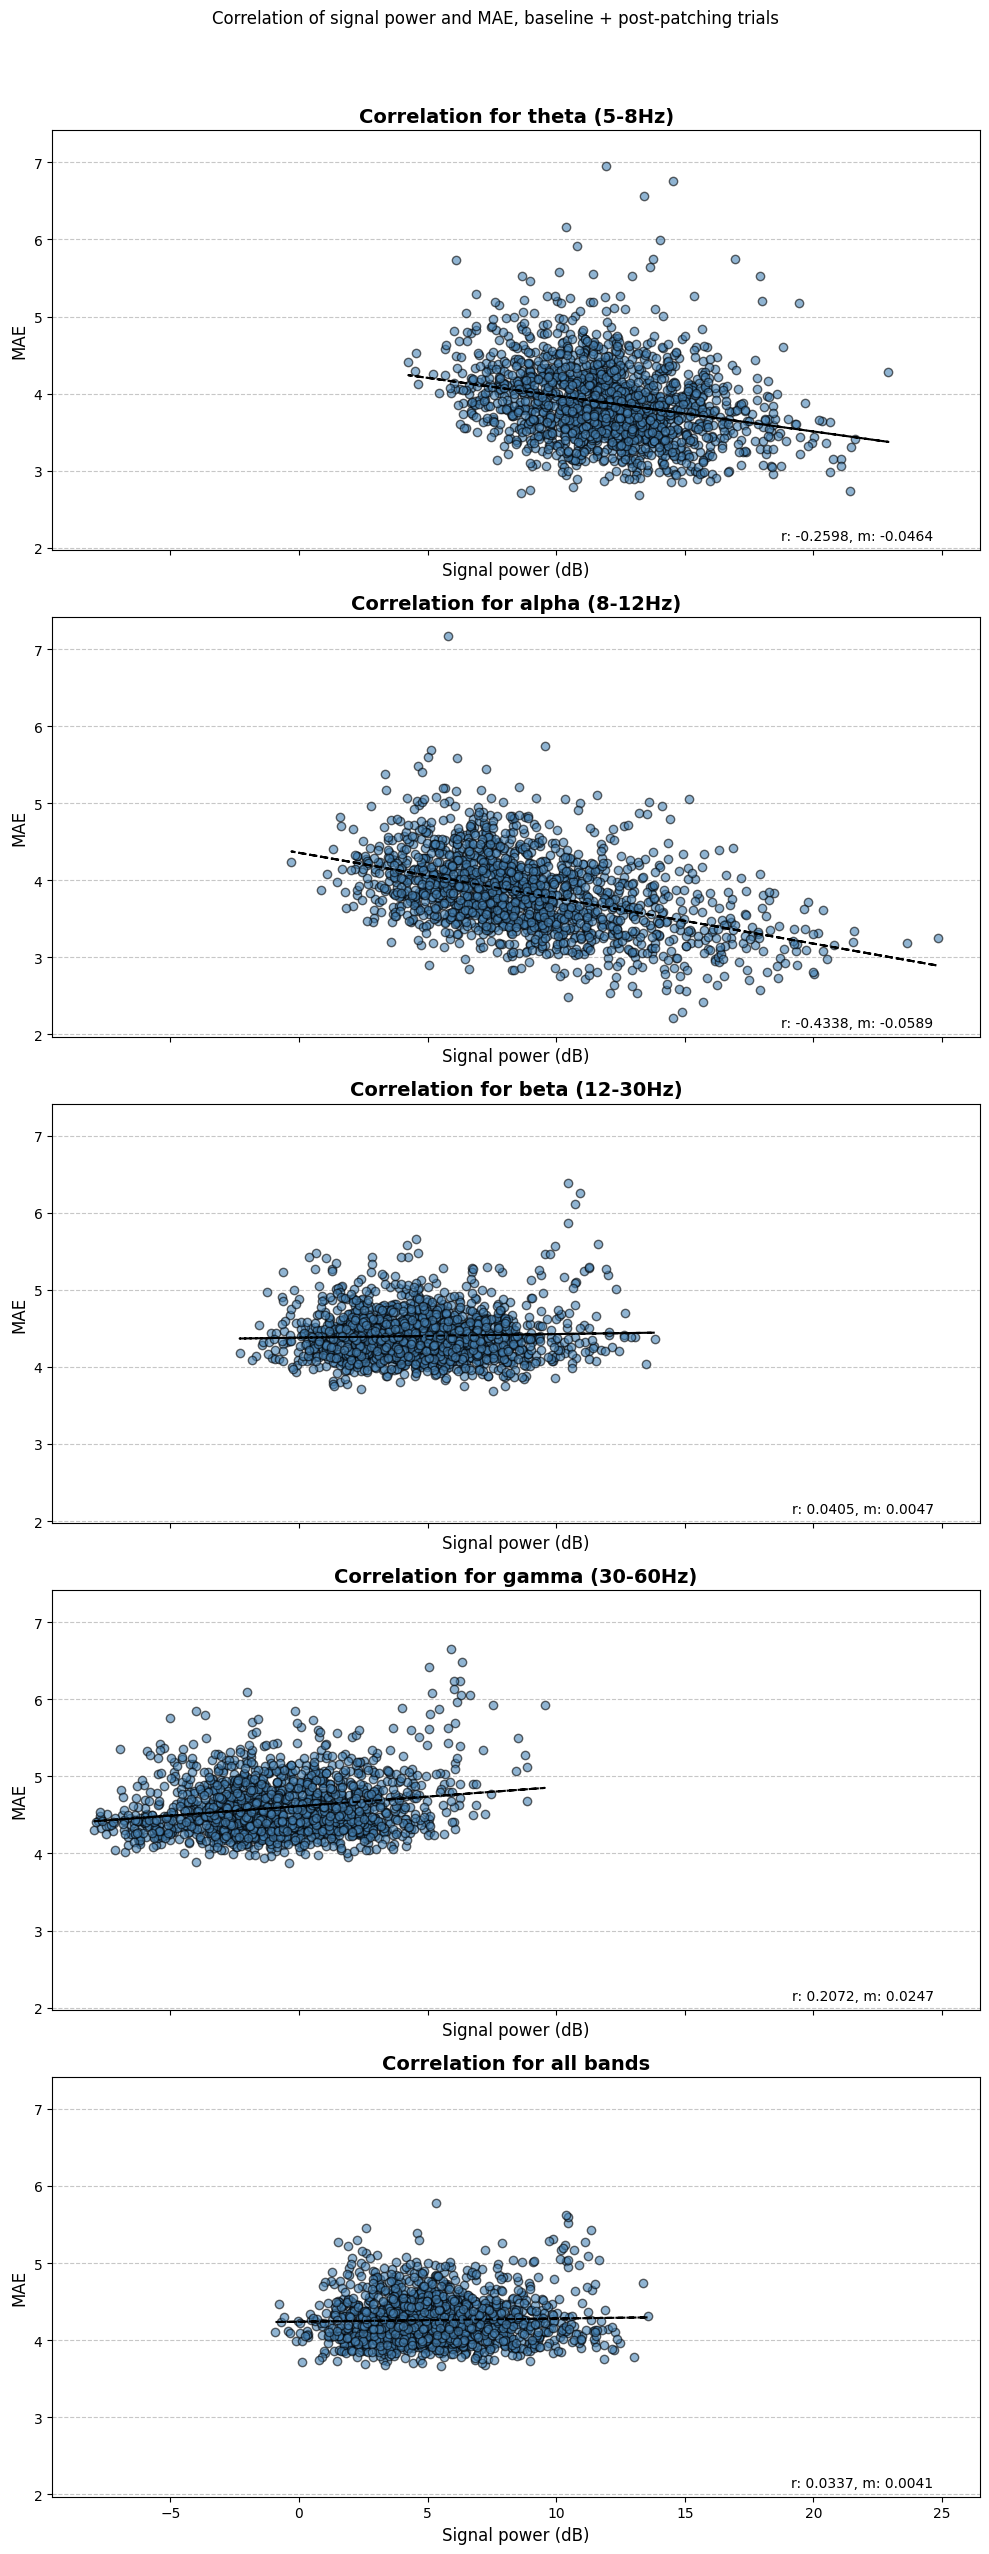

In [27]:
all_trials = baseline_merged + postpatch_merged
vols = data_processor.extract_metric(all_trials, "signal_mean_bandwise", bands, bandwise=True)
vols["all bands"] = data_processor.extract_metric(all_trials, "signal_mean")

for metric, label in [("corrected_mae", "corrected MAE"), ("mae", "MAE")]:
    errors = data_processor.extract_metric(all_trials, f"{metric}_bandwise", bands, bandwise=True)
    errors["all bands"] = data_processor.extract_metric(all_trials, metric)
    plotting.correlation_plot(x=vols, y=errors, title=f'Correlation of signal power and {label}, baseline + post-patching trials',
                              xlabel='Signal power (dB)', ylabel=label,
                              save_dir=plot_root / "correlation_plots", save_name=f"{metric}_correlation_{an_suffix}_{excl_suffix}")


## Effect of the power correction (MAE, NMAE, corrected MAE)

### Power vs. error before and after the correction
Pooled trials of all subjects, with a separate fitted line per session. The corrected MAE subtracts the within-subject
dependence on power fitted by `fill_corrected_maes`, NMAE divides by the signal volatility. As in the plot above, the lines
mix within- and between-subject variation, so the corrected MAE keeps the between-subject part. Each panel has its own y
scale, as the metrics have different units.

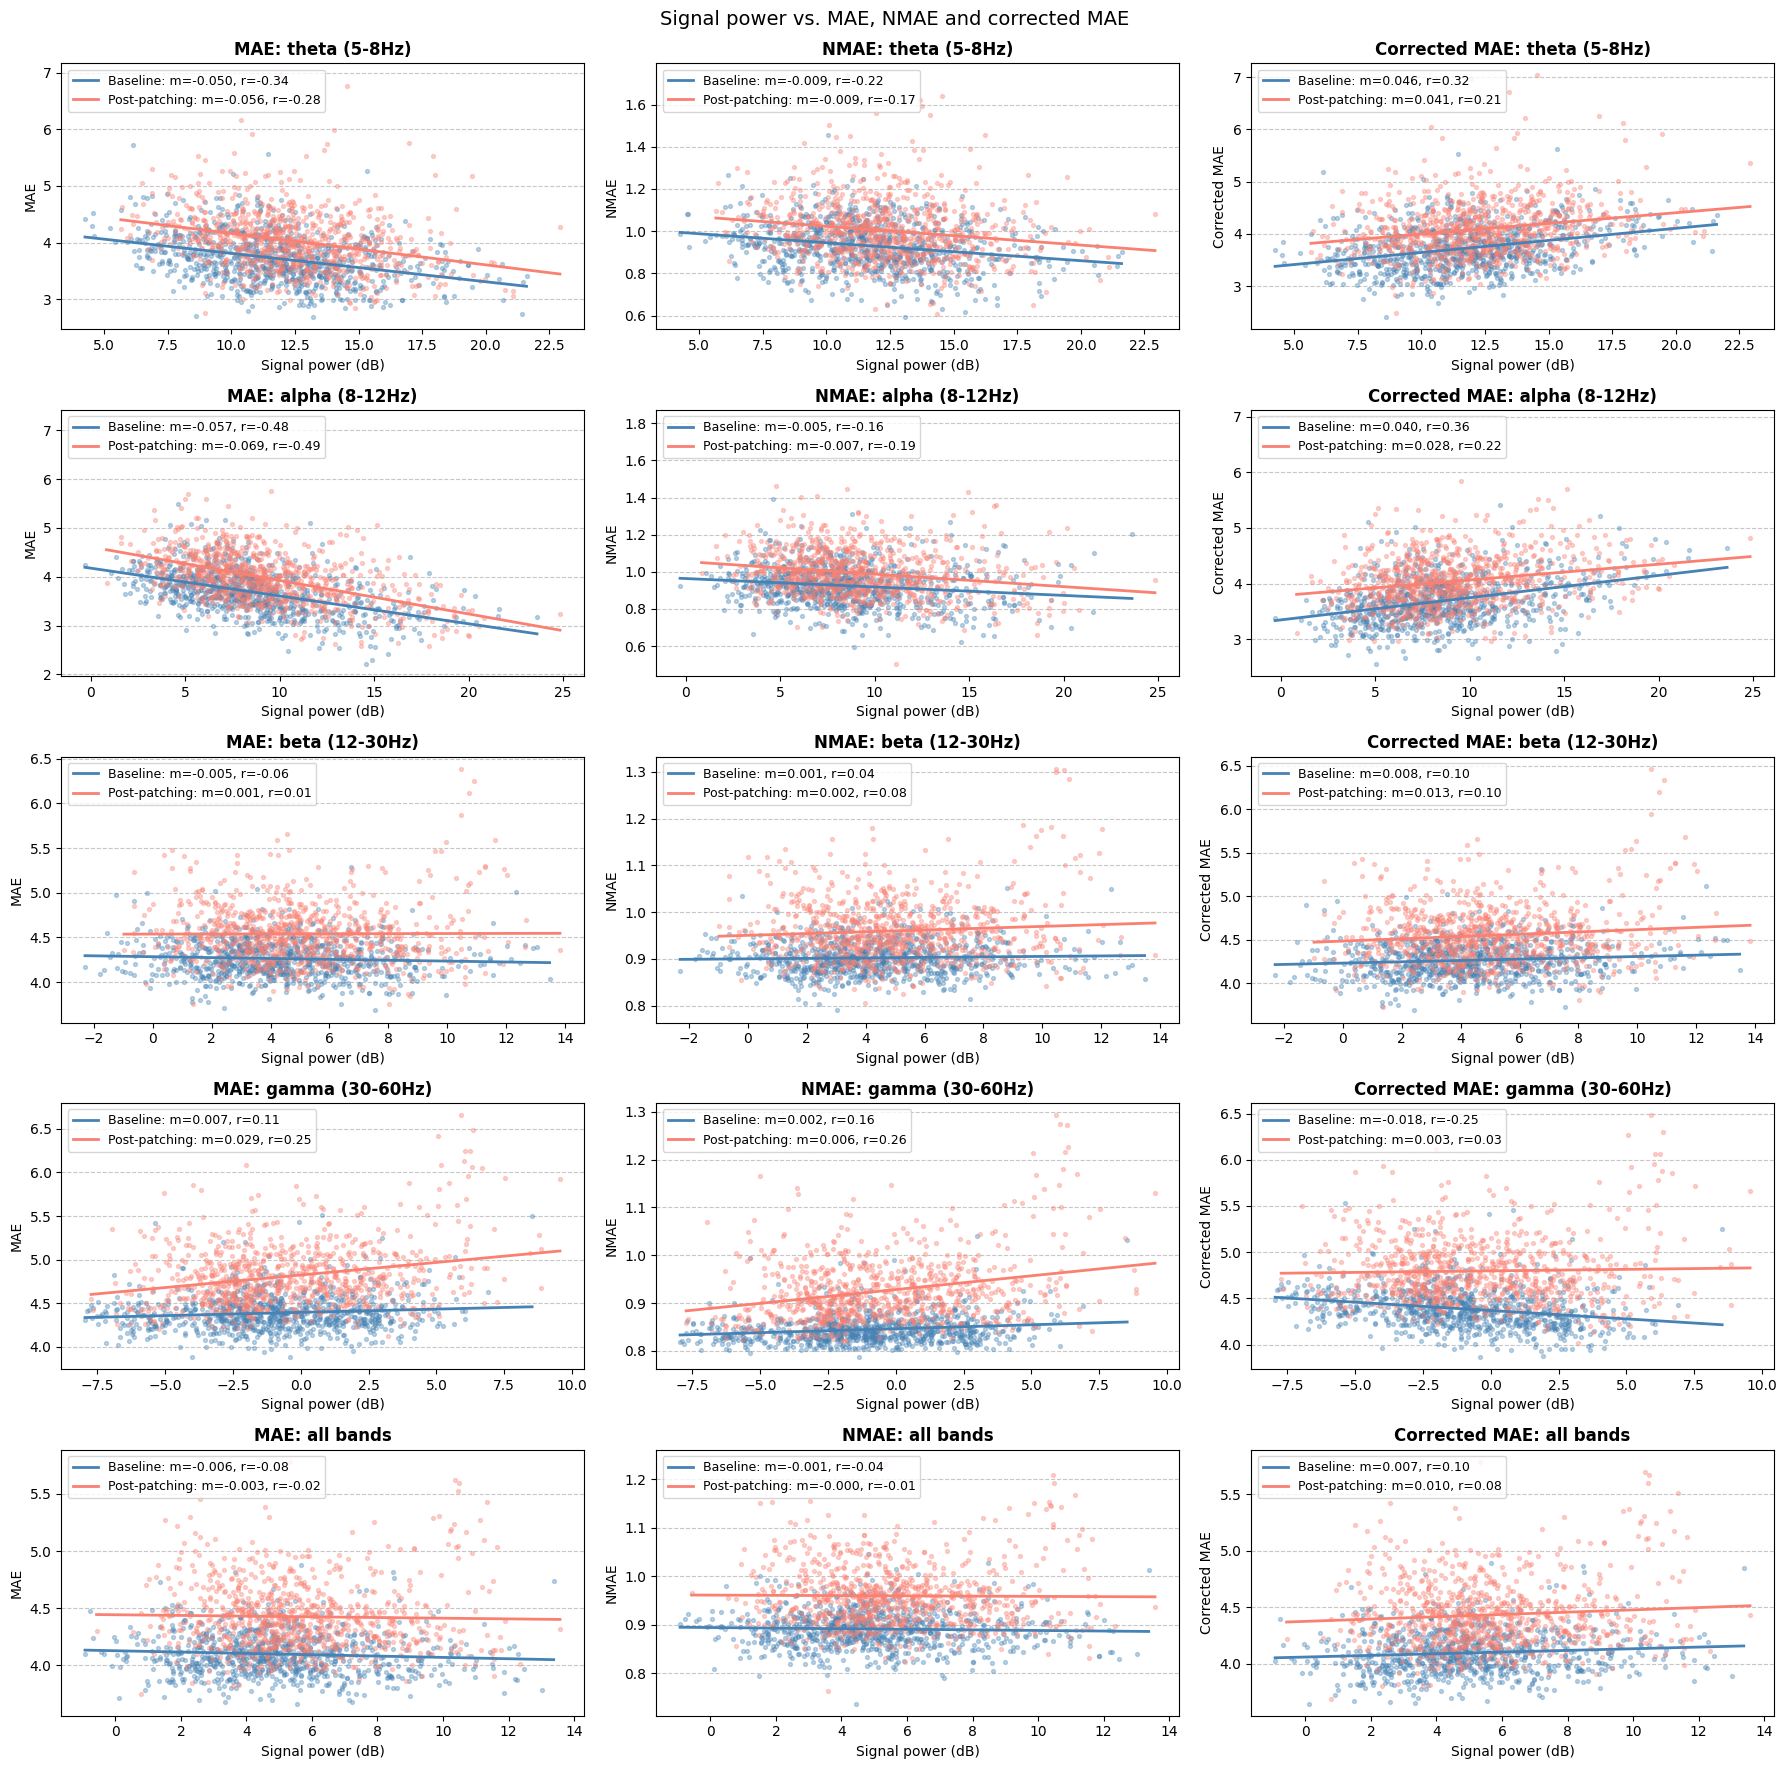

In [28]:
metrics_to_compare = {"MAE": "mae", "NMAE": "nmae", "Corrected MAE": "corrected_mae"}
band_keys = [*bands, "all bands"]

powers, errors = {}, {label: {} for label in metrics_to_compare}
for session, trials in [("Baseline", baseline_merged), ("Post-patching", postpatch_merged)]:
    powers[session] = data_processor.extract_metric(trials, "signal_mean_bandwise", bands, bandwise=True)
    powers[session]["all bands"] = data_processor.extract_metric(trials, "signal_mean")
    for label, metric in metrics_to_compare.items():
        errors[label][session] = data_processor.extract_metric(trials, f"{metric}_bandwise", bands, bandwise=True)
        errors[label][session]["all bands"] = data_processor.extract_metric(trials, metric)

plotting.session_correlation_plot(x_by_session=powers, y_by_metric=errors, xlabel="Signal power (dB)", sharey=False,
                                  title="Signal power vs. MAE, NMAE and corrected MAE",
                                  save_dir=plot_root / "correlation_plots", save_name=f"mae_correction_correlation_{an_suffix}_{excl_suffix}")


### Change of MAE, NMAE and corrected MAE after patching
Subject means per session. Bars show the mean of the subject differences (post-patching - baseline) ± SEM, in % of the mean baseline value of each metric, so the three metrics are comparable. The p-values are paired t-tests on the subject means.

band             |             MAE %      p |            NMAE %      p |   Corrected MAE %      p
theta (5-8Hz)    |             +8.32  0.000 |             +7.78  0.000 |             +9.89  0.000
alpha (8-12Hz)   |             +7.91  0.000 |             +7.37  0.000 |             +9.57  0.000
beta (12-30Hz)   |             +6.60  0.000 |             +6.43  0.000 |             +6.80  0.000
gamma (30-60Hz)  |             +9.65  0.000 |             +9.58  0.000 |             +9.32  0.000
all bands        |             +8.01  0.000 |             +7.71  0.000 |             +8.22  0.000


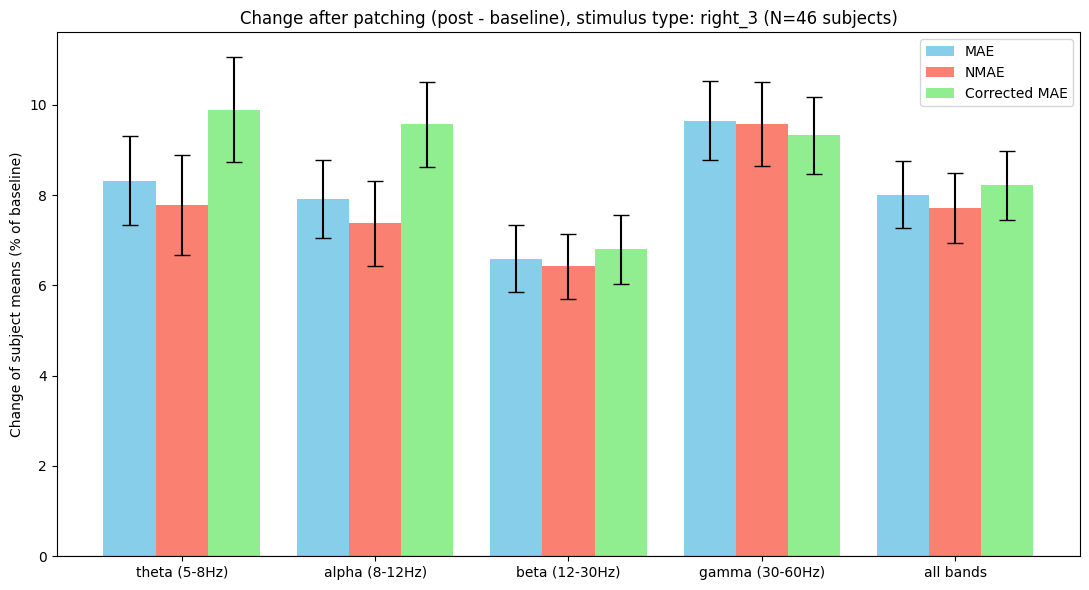

In [29]:
# raw change of the subject means per metric: mean ± SEM of the subject differences in % of the mean baseline, paired t-test
raw_changes = {}
for label, metric in metrics_to_compare.items():
    b_means, _ = data_processor.calc_subjectwise_metric_stats(baseline_merged, bands, metric)
    p_means, _ = data_processor.calc_subjectwise_metric_stats(postpatch_merged, bands, metric)
    subjects = [s for s in b_means if s in p_means]
    pre = np.array([[b_means[s][b] for b in band_keys] for s in subjects])
    post = np.array([[p_means[s][b] for b in band_keys] for s in subjects])
    scale = 100 / pre.mean(axis=0)
    raw_changes[label] = ((post - pre).mean(axis=0) * scale, sem(post - pre) * scale, ttest_rel(post, pre).pvalue)

print(f"{'band':16s}" + "".join(f" | {label + ' %':>17s} {'p':>6s}" for label in raw_changes))
for i, band in enumerate(band_keys):
    print(f"{band:16s}" + "".join(f" | {changes[i]:+17.2f} {ps[i]:6.3f}" for changes, _, ps in raw_changes.values()))

fig, ax = plt.subplots(figsize=(11, 6))
plotting.plot_grouped_bar(x_text=band_keys, width=0.27, means=[changes for changes, _, _ in raw_changes.values()],
                          sems=[sems for _, sems, _ in raw_changes.values()], labels=list(raw_changes.keys()),
                          title=f'Change after patching (post - baseline), stimulus type: {", ".join(conditions)}',
                          y_label="Change of subject means (% of baseline)", n_text=f"N={len(subjects)} subjects", ax=ax, fig=fig)
ax.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plotting.save_button(fig, save_dir=plot_root / "bandwise_e_mae_comparison", default_name=f"mae_correction_difference_{an_suffix}_{excl_suffix}")
plt.show()
